In [ ]:
# ============================================================
# CELL 1 — Install dependencies and mount Google Drive
# ============================================================
from google.colab import drive, files
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import io
import warnings
warnings.filterwarnings('ignore')

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'
import os
os.makedirs(DRIVE_PATH, exist_ok=True)

print("Drive mounted.")
print(f"Output folder: {DRIVE_PATH}")

Mounted at /content/drive
Drive mounted.
Output folder: /content/drive/My Drive/Colab Notebooks/V3/


In [ ]:
# ============================================================
# CELL 2 — Upload the V3_dataset.xlsx from your laptop
# ============================================================
print("Select V3_dataset.xlsx from your laptop...")
uploaded = files.upload()
filename = list(uploaded.keys())[0]
print(f"Uploaded: {filename}")

xl = pd.ExcelFile(io.BytesIO(uploaded[filename]))
print(f"\nSheets found: {xl.sheet_names}")

Select V3_dataset.xlsx from your laptop...


Saving V3 dataset.xlsx to V3 dataset.xlsx
Uploaded: V3 dataset.xlsx

Sheets found: ['Abuja- Wuse', 'Bauchi- Wunti', 'Kano- Sabongeri', 'Lagos- Balogun', 'Port-Harcourt', 'Onitsha', 'Abuja Petrol', 'Abuja- Transport', 'Bauchi Petrol', 'Bauchi Transport', 'Kano Petrol', 'Kano Transport', 'Lagos Petrol', 'Lagos-Transport', 'Onitsha-Petrol', 'Onitsha Transport', 'Port Harcourt-Petrol', 'Port Harcourt Transport', 'NGN-USD rate', 'CBN Interest Rate']


In [ ]:
# ============================================================
# CELL 3 — Define sheet groupings and clean names
# ============================================================

# City food sheets — map sheet name to clean city name
FOOD_SHEETS = {
    'Abuja- Wuse':      'Abuja',
    'Bauchi- Wunti':    'Bauchi',
    'Kano- Sabongeri':  'Kano',
    'Lagos- Balogun':   'Lagos',
    'Port-Harcourt':    'Port_Harcourt',
    'Onitsha':          'Onitsha',
}

# Petrol sheets
PETROL_SHEETS = {
    'Abuja Petrol':           'Abuja',
    'Bauchi Petrol':          'Bauchi',
    'Kano Petrol':            'Kano',
    'Lagos Petrol':           'Lagos',
    'Onitsha-Petrol':         'Onitsha',
    'Port Harcourt-Petrol':   'Port_Harcourt',
}

# Transport sheets
TRANSPORT_SHEETS = {
    'Abuja- Transport':           'Abuja',
    'Bauchi Transport':           'Bauchi',
    'Kano Transport':             'Kano',
    'Lagos-Transport':            'Lagos',
    'Onitsha Transport':          'Onitsha',
    'Port Harcourt Transport':    'Port_Harcourt',
}

# National sheets
NATIONAL_SHEETS = {
    'NGN-USD rate':      'USD_NGN',
    'CBN Interest Rate': 'CBN_MPR',
}

# Ingredient name cleaning — strip city prefix and standardise
def clean_indicator(indicator, city):
    """Remove city name prefix and standardise indicator to short name."""
    # Remove city name prefix variants
    for prefix in [city, city.replace('_', ' '), city.replace('_', '-')]:
        indicator = indicator.replace(prefix, '').strip()

    # Standardise to short clean names
    mapping = {
        'Rice (1 derica, ~0.4kg)':              'Rice',
        'Rice':                                  'Rice',
        'Salt (250g)':                           'Salt',
        'Salt':                                  'Salt',
        'Seasoning (Knorr, 1 sachet)':          'Seasoning',
        'Seasoning':                             'Seasoning',
        'Curry (25g)':                           'Curry',
        'Curry':                                 'Curry',
        'Thyme (25g)':                           'Thyme',
        'Thyme':                                 'Thyme',
        'Red peppers (160g cup)':               'Red_Peppers',
        'Red peppers':                           'Red_Peppers',
        'Tomatoes, fresh (piece count varies)': 'Tomatoes_Fresh',
        'Tomatoes, fresh':                      'Tomatoes_Fresh',
        'Vegetable oil (90cl)':                 'Veg_Oil',
        'Vegetable oil':                        'Veg_Oil',
        'Tinned tomatoes (70g tin)':            'Tinned_Tomatoes',
        'Tinned tomatoes':                      'Tinned_Tomatoes',
        'Beef (1kg)':                           'Beef',
        'Beef':                                 'Beef',
        'Chicken (1kg)':                        'Chicken',
        'Chicken':                              'Chicken',
        'Onions (piece count varies - see Notes)': 'Onions',
        'Onions':                               'Onions',
    }
    for key, val in mapping.items():
        if key.lower() in indicator.lower():
            return val
    return indicator.strip()

print("Sheet mappings defined.")
print(f"Food sheets: {list(FOOD_SHEETS.keys())}")
print(f"Petrol sheets: {list(PETROL_SHEETS.keys())}")
print(f"Transport sheets: {list(TRANSPORT_SHEETS.keys())}")

Sheet mappings defined.
Food sheets: ['Abuja- Wuse', 'Bauchi- Wunti', 'Kano- Sabongeri', 'Lagos- Balogun', 'Port-Harcourt', 'Onitsha']
Petrol sheets: ['Abuja Petrol', 'Bauchi Petrol', 'Kano Petrol', 'Lagos Petrol', 'Onitsha-Petrol', 'Port Harcourt-Petrol']
Transport sheets: ['Abuja- Transport', 'Bauchi Transport', 'Kano Transport', 'Lagos-Transport', 'Onitsha Transport', 'Port Harcourt Transport']


In [ ]:
# ============================================================
# CELL 4 — Parse datetime helper
# Handles "Year" + "Time Period" (month name) columns
# ============================================================

MONTH_MAP = {
    'January': 1, 'February': 2, 'March': 3,
    'April': 4, 'May': 5, 'June': 6,
    'July': 7, 'August': 8, 'September': 9,
    'October': 10, 'November': 11, 'December': 12
}

def parse_date(row):
    """Convert Year + Time Period columns to datetime."""
    try:
        year  = int(row['Year'])
        month = MONTH_MAP.get(str(row['Time Period']).strip(), None)
        if month is None:
            return pd.NaT
        return pd.Timestamp(year=year, month=month, day=1)
    except:
        return pd.NaT

print("Date parser defined.")

Date parser defined.


In [ ]:
# ============================================================
# CELL 5 — Load and concatenate FOOD sheets into long format
# ============================================================

food_frames = []

for sheet_name, city_name in FOOD_SHEETS.items():
    try:
        df = xl.parse(sheet_name)
        df.columns = [str(c).strip() for c in df.columns]

        # Parse date
        df['date'] = df.apply(parse_date, axis=1)
        df = df.dropna(subset=['date'])

        # Add city column
        df['city'] = city_name

        # Clean indicator to short name
        df['variable'] = df['Indicator'].apply(
            lambda x: clean_indicator(str(x), city_name)
        )
        df['value'] = pd.to_numeric(df['Value'], errors='coerce')

        food_frames.append(df[['date', 'city', 'variable', 'value']])
        print(f"  {sheet_name} → {city_name}: {len(df)} rows")
    except Exception as e:
        print(f"  ERROR on {sheet_name}: {e}")

food_long = pd.concat(food_frames, ignore_index=True)
print(f"\nFood long format: {food_long.shape}")
print(food_long.head())

  Abuja- Wuse → Abuja: 996 rows
  Bauchi- Wunti → Bauchi: 768 rows
  Kano- Sabongeri → Kano: 804 rows
  Lagos- Balogun → Lagos: 984 rows
  Port-Harcourt → Port_Harcourt: 864 rows
  Onitsha → Onitsha: 996 rows

Food long format: (5412, 4)
        date   city   variable  value
0 2019-01-01  Abuja       Rice  800.0
1 2019-01-01  Abuja       Salt  200.0
2 2019-01-01  Abuja  Seasoning  800.0
3 2019-01-01  Abuja      Curry  350.0
4 2019-01-01  Abuja      Thyme  350.0


In [ ]:
# ============================================================
# CELL 6 — Load PETROL sheets
# ============================================================

petrol_frames = []

for sheet_name, city_name in PETROL_SHEETS.items():
    try:
        df = xl.parse(sheet_name)
        df.columns = [str(c).strip() for c in df.columns]
        df['date'] = df.apply(parse_date, axis=1)
        df = df.dropna(subset=['date'])
        df['city'] = city_name
        df['variable'] = 'PMS_Price'
        df['value'] = pd.to_numeric(df['Value'], errors='coerce')
        petrol_frames.append(df[['date', 'city', 'variable', 'value']])
        print(f"  {sheet_name} → {city_name}: {len(df)} rows")
    except Exception as e:
        print(f"  ERROR on {sheet_name}: {e}")

petrol_long = pd.concat(petrol_frames, ignore_index=True)
print(f"\nPetrol long format: {petrol_long.shape}")

  Abuja Petrol → Abuja: 89 rows
  Bauchi Petrol → Bauchi: 89 rows
  Kano Petrol → Kano: 89 rows
  Lagos Petrol → Lagos: 89 rows
  Onitsha-Petrol → Onitsha: 89 rows
  Port Harcourt-Petrol → Port_Harcourt: 89 rows

Petrol long format: (534, 4)


In [ ]:
# ============================================================
# CELL 7 — Load TRANSPORT sheets
# ============================================================

transport_frames = []

for sheet_name, city_name in TRANSPORT_SHEETS.items():
    try:
        df = xl.parse(sheet_name)
        df.columns = [str(c).strip() for c in df.columns]
        df['date'] = df.apply(parse_date, axis=1)
        df = df.dropna(subset=['date'])
        df['city'] = city_name
        df['variable'] = 'Bus_Intercity'
        df['value'] = pd.to_numeric(df['Value'], errors='coerce')
        transport_frames.append(df[['date', 'city', 'variable', 'value']])
        print(f"  {sheet_name} → {city_name}: {len(df)} rows")
    except Exception as e:
        print(f"  ERROR on {sheet_name}: {e}")

transport_long = pd.concat(transport_frames, ignore_index=True)
print(f"\nTransport long format: {transport_long.shape}")

  Abuja- Transport → Abuja: 89 rows
  Bauchi Transport → Bauchi: 89 rows
  Kano Transport → Kano: 89 rows
  Lagos-Transport → Lagos: 89 rows
  Onitsha Transport → Onitsha: 89 rows
  Port Harcourt Transport → Port_Harcourt: 89 rows

Transport long format: (534, 4)


In [ ]:
# ============================================================
# CELL 8 — Load NATIONAL sheets (USD/NGN and CBN MPR)
# These are national level — will be broadcast to all cities
# ============================================================

national_frames = []

for sheet_name, var_name in NATIONAL_SHEETS.items():
    try:
        df = xl.parse(sheet_name)
        df.columns = [str(c).strip() for c in df.columns]
        df['date'] = df.apply(parse_date, axis=1)
        df = df.dropna(subset=['date'])
        df['variable'] = var_name
        df['value'] = pd.to_numeric(df['Value'], errors='coerce')
        national_frames.append(df[['date', 'variable', 'value']])
        print(f"  {sheet_name} → {var_name}: {len(df)} rows")
    except Exception as e:
        print(f"  ERROR on {sheet_name}: {e}")

national_long = pd.concat(national_frames, ignore_index=True)

# Pivot national data to wide: date as index, variables as columns
national_wide = national_long.pivot_table(
    index='date', columns='variable', values='value', aggfunc='mean'
).reset_index()

print(f"\nNational wide format: {national_wide.shape}")
print(national_wide.head())

  NGN-USD rate → USD_NGN: 90 rows
  CBN Interest Rate → CBN_MPR: 90 rows

National wide format: (90, 3)
variable       date  CBN_MPR  USD_NGN
0        2019-01-01     14.0   306.25
1        2019-02-01     14.0   306.35
2        2019-03-01     13.5   306.45
3        2019-04-01     13.5   306.40
4        2019-05-01     13.5   306.45


In [ ]:
# ============================================================
# CELL 9 — Combine all city-level data into one long frame
# ============================================================

city_long = pd.concat([food_long, petrol_long, transport_long],
                       ignore_index=True)

print(f"Combined city long format: {city_long.shape}")
print(f"Cities: {sorted(city_long['city'].unique())}")
print(f"Variables: {sorted(city_long['variable'].unique())}")
print(f"Date range: {city_long['date'].min()} to {city_long['date'].max()}")

Combined city long format: (6480, 4)
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Variables: ['Beef', 'Bus_Intercity', 'Chicken', 'Curry', 'Onions', 'PMS_Price', 'Red_Peppers', 'Rice', 'Salt', 'Seasoning', 'Thyme', 'Tinned_Tomatoes', 'Tomatoes_Fresh', 'Veg_Oil']
Date range: 2019-01-01 00:00:00 to 2026-06-01 00:00:00


In [ ]:
# ============================================================
# CELL 10 — Pivot city data to WIDE FORMAT
# One row per city-month, all variables as columns
# ============================================================

city_wide = city_long.pivot_table(
    index=['date', 'city'],
    columns='variable',
    values='value',
    aggfunc='mean'
).reset_index()

# Flatten column names
city_wide.columns.name = None
city_wide.columns = [str(c).strip() for c in city_wide.columns]

print(f"City wide format: {city_wide.shape}")
print(f"Columns: {list(city_wide.columns)}")
print(city_wide.head())

City wide format: (540, 16)
Columns: ['date', 'city', 'Beef', 'Bus_Intercity', 'Chicken', 'Curry', 'Onions', 'PMS_Price', 'Red_Peppers', 'Rice', 'Salt', 'Seasoning', 'Thyme', 'Tinned_Tomatoes', 'Tomatoes_Fresh', 'Veg_Oil']
        date     city    Beef  Bus_Intercity  Chicken  Curry  Onions  \
0 2019-01-01    Abuja  2000.0    4100.000000   1800.0  350.0   200.0   
1 2019-01-01   Bauchi     NaN     958.333333      NaN    NaN     NaN   
2 2019-01-01     Kano   800.0    1203.333333   1650.0  280.0    20.0   
3 2019-01-01    Lagos  1000.0    2105.555556   1200.0  300.0   100.0   
4 2019-01-01  Onitsha   500.0    1495.000000   1400.0  290.0   100.0   

    PMS_Price  Red_Peppers   Rice   Salt  Seasoning  Thyme  Tinned_Tomatoes  \
0  144.200000        150.0  800.0  200.0      800.0  350.0             70.0   
1  145.250000          NaN    NaN    NaN        NaN    NaN              NaN   
2  145.000000         50.0  500.0  100.0      650.0  280.0             70.0   
3  144.866667         50.0  

In [ ]:
# ============================================================
# CELL 11 — Join national indicators to city wide format
# USD_NGN and CBN_MPR broadcast to all 6 cities per month
# ============================================================

master = city_wide.merge(national_wide, on='date', how='left')

print(f"Master shape after national join: {master.shape}")
print(f"Columns: {list(master.columns)}")
print(master.head())

Master shape after national join: (540, 18)
Columns: ['date', 'city', 'Beef', 'Bus_Intercity', 'Chicken', 'Curry', 'Onions', 'PMS_Price', 'Red_Peppers', 'Rice', 'Salt', 'Seasoning', 'Thyme', 'Tinned_Tomatoes', 'Tomatoes_Fresh', 'Veg_Oil', 'CBN_MPR', 'USD_NGN']
        date     city    Beef  Bus_Intercity  Chicken  Curry  Onions  \
0 2019-01-01    Abuja  2000.0    4100.000000   1800.0  350.0   200.0   
1 2019-01-01   Bauchi     NaN     958.333333      NaN    NaN     NaN   
2 2019-01-01     Kano   800.0    1203.333333   1650.0  280.0    20.0   
3 2019-01-01    Lagos  1000.0    2105.555556   1200.0  300.0   100.0   
4 2019-01-01  Onitsha   500.0    1495.000000   1400.0  290.0   100.0   

    PMS_Price  Red_Peppers   Rice   Salt  Seasoning  Thyme  Tinned_Tomatoes  \
0  144.200000        150.0  800.0  200.0      800.0  350.0             70.0   
1  145.250000          NaN    NaN    NaN        NaN    NaN              NaN   
2  145.000000         50.0  500.0  100.0      650.0  280.0           

In [ ]:
# ============================================================
# CELL 12 — Gap filling
# December missing in some years — forward fill within each city
# Also fill any other sporadic NaN values
# ============================================================

# Sort by city then date
master = master.sort_values(['city', 'date']).reset_index(drop=True)

# Build complete date spine — every month from Jan 2019 to Jun 2026
all_dates  = pd.date_range(start='2019-01-01', end='2026-06-01', freq='MS')
all_cities = master['city'].unique()

# Create full grid of city × month
full_grid = pd.MultiIndex.from_product(
    [all_dates, all_cities], names=['date', 'city']
).to_frame(index=False)

# Merge master onto full grid
master_full = full_grid.merge(master, on=['date', 'city'], how='left')
master_full = master_full.sort_values(['city', 'date']).reset_index(drop=True)

# Forward fill within each city group (fills December gaps and sporadic NaN)
food_transport_cols = [c for c in master_full.columns
                       if c not in ['date', 'city']]

master_full[food_transport_cols] = (
    master_full.groupby('city')[food_transport_cols]
    .transform(lambda x: x.ffill().bfill())
)

print(f"Master full shape: {master_full.shape}")
print(f"Date range: {master_full['date'].min()} to {master_full['date'].max()}")
print(f"Cities: {sorted(master_full['city'].unique())}")
print(f"Missing values after gap fill:")
print(master_full.isnull().sum()[master_full.isnull().sum() > 0])

Master full shape: (540, 18)
Date range: 2019-01-01 00:00:00 to 2026-06-01 00:00:00
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Missing values after gap fill:
Series([], dtype: int64)


In [ ]:
# ============================================================
# CELL 13 — Final validation checks
# ============================================================

print("=" * 60)
print("FINAL VALIDATION REPORT")
print("=" * 60)

print(f"\nShape: {master_full.shape}")
print(f"Rows per city:")
print(master_full.groupby('city').size())

print(f"\nDate range: {master_full['date'].min()} to {master_full['date'].max()}")
expected_months = len(pd.date_range('2019-01-01', '2026-06-01', freq='MS'))
print(f"Expected months per city: {expected_months}")
print(f"Actual months per city:")
print(master_full.groupby('city')['date'].count())

print(f"\nAll columns:")
for col in master_full.columns:
    n_missing = master_full[col].isnull().sum()
    pct = 100 * n_missing / len(master_full)
    print(f"  {col:<30} missing: {n_missing} ({pct:.1f}%)")

print(f"\nSample — Abuja, January 2019:")
sample = master_full[
    (master_full['city'] == 'Abuja') &
    (master_full['date'] == '2019-01-01')
]
print(sample.T)

print(f"\nSample — June 2023 (fuel subsidy removal month):")
sample2 = master_full[master_full['date'] == '2023-06-01']
print(sample2[['city', 'Tomatoes_Fresh', 'PMS_Price',
               'Bus_Intercity', 'USD_NGN', 'CBN_MPR']])

FINAL VALIDATION REPORT

Shape: (540, 18)
Rows per city:
city
Abuja            90
Bauchi           90
Kano             90
Lagos            90
Onitsha          90
Port_Harcourt    90
dtype: int64

Date range: 2019-01-01 00:00:00 to 2026-06-01 00:00:00
Expected months per city: 90
Actual months per city:
city
Abuja            90
Bauchi           90
Kano             90
Lagos            90
Onitsha          90
Port_Harcourt    90
Name: date, dtype: int64

All columns:
  date                           missing: 0 (0.0%)
  city                           missing: 0 (0.0%)
  Beef                           missing: 0 (0.0%)
  Bus_Intercity                  missing: 0 (0.0%)
  Chicken                        missing: 0 (0.0%)
  Curry                          missing: 0 (0.0%)
  Onions                         missing: 0 (0.0%)
  PMS_Price                      missing: 0 (0.0%)
  Red_Peppers                    missing: 0 (0.0%)
  Rice                           missing: 0 (0.0%)
  Salt                

In [ ]:
# ============================================================
# CELL 14 — Save master CSV to Google Drive
# ============================================================

output_path = DRIVE_PATH + 'V3_Master_Wide.csv'
master_full.to_csv(output_path, index=False)
print(f"Saved to Google Drive: {output_path}")
print(f"Shape: {master_full.shape}")
print(f"Size: {master_full.memory_usage(deep=True).sum() / 1024:.1f} KB")

# Also show how to reload it in any future notebook
print("\nTo reload in any future Colab notebook:")
print("  from google.colab import drive")
print("  drive.mount('/content/drive')")
print("  import pandas as pd")
print(f"  df = pd.read_csv('{output_path}', parse_dates=['date'])")

Saved to Google Drive: /content/drive/My Drive/Colab Notebooks/V3/V3_Master_Wide.csv
Shape: (540, 18)
Size: 101.2 KB

To reload in any future Colab notebook:
  from google.colab import drive
  drive.mount('/content/drive')
  import pandas as pd
  df = pd.read_csv('/content/drive/My Drive/Colab Notebooks/V3/V3_Master_Wide.csv', parse_dates=['date'])


In [ ]:
# ============================================================
# LOAD V3_Master_Wide.csv from Google Drive
# Run this at the start of every future notebook
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'

df = pd.read_csv(DRIVE_PATH + 'V3_Master_Wide.csv', parse_dates=['date'])

# Set date as index for time series work
df = df.sort_values(['city', 'date']).reset_index(drop=True)

print(f"Shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"Cities: {sorted(df['city'].unique())}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Months per city: {df.groupby('city').size().iloc[0]}")
print()
print("First 20 rows:")
print(df.head(20).to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (540, 18)
Columns: ['date', 'city', 'Beef', 'Bus_Intercity', 'Chicken', 'Curry', 'Onions', 'PMS_Price', 'Red_Peppers', 'Rice', 'Salt', 'Seasoning', 'Thyme', 'Tinned_Tomatoes', 'Tomatoes_Fresh', 'Veg_Oil', 'CBN_MPR', 'USD_NGN']
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Date range: 2019-01-01 00:00:00 to 2026-06-01 00:00:00
Months per city: 90

First 20 rows:
         date   city    Beef  Bus_Intercity  Chicken  Curry  Onions   PMS_Price  Red_Peppers    Rice   Salt  Seasoning  Thyme  Tinned_Tomatoes  Tomatoes_Fresh  Veg_Oil  CBN_MPR  USD_NGN
0  2019-01-01  Abuja  2000.0         4100.0   1800.0  350.0   200.0  144.200000        150.0   800.0  200.0      800.0  350.0             70.0           200.0    550.0     14.0   306.25
1  2019-02-01  Abuja  2000.0         4000.0   1800.0  350.0   200.0  144.500000        150.0   800.0 

In [ ]:
# ============================================================
# STAGE 1 — TAKENS EMBEDDING
# V3 Nigeria Food Price Intelligence
# Runs on ALL indicators per city + national indicators
# Produces: τ and d per indicator per city
#           Multivariate reconstructed phase space per city
#           Full parameter table saved to Drive
# ============================================================

# CELL 1 — Install and import
# ============================================================
!pip install giotto-tda -q

from google.colab import drive, files
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.signal import argrelmin
from scipy.spatial.distance import cdist
from itertools import combinations
import warnings
warnings.filterwarnings('ignore')

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'

df = pd.read_csv(
    DRIVE_PATH + 'V3_Master_Wide.csv',
    parse_dates=['date']
)
df = df.sort_values(['city', 'date']).reset_index(drop=True)

CITIES = sorted(df['city'].unique())

# All city-level indicators (14 per city)
CITY_INDICATORS = [
    'Rice', 'Salt', 'Seasoning', 'Curry', 'Thyme',
    'Red_Peppers', 'Tomatoes_Fresh', 'Veg_Oil',
    'Tinned_Tomatoes', 'Beef', 'Chicken', 'Onions',
    'PMS_Price', 'Bus_Intercity'
]

# National indicators (2 — no city variation)
NATIONAL_INDICATORS = ['USD_NGN', 'CBN_MPR']

print(f"Cities: {CITIES}")
print(f"City-level indicators: {len(CITY_INDICATORS)}")
print(f"National indicators:   {len(NATIONAL_INDICATORS)}")
print(f"Total embeddings:      {len(CITIES) * len(CITY_INDICATORS) + len(NATIONAL_INDICATORS)}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Shape: {df.shape}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.8/99.8 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 49.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 41.8 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for giotto-tda
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (giotto-tda)
Mounted at /content/drive
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
City-level indicators: 14
National indicators:   2
Total embeddings:      86
Date range: 2019-01-01 00:00:00 to 2026-06-01 00:00:00
Shape: (540, 18)


In [ ]:
# ============================================================
# CELL 2 — Core embedding functions
# ============================================================

def average_mutual_information(series, max_lag=12):
    """
    Compute AMI between series and its lagged versions.
    First local minimum = optimal τ.
    Uses histogram-based mutual information estimation.
    """
    series = np.array(series, dtype=float)
    # Remove NaN
    series = series[~np.isnan(series)]
    if len(series) < 20:
        return np.zeros(max_lag)

    n = len(series)
    ami_values = []

    for lag in range(1, max_lag + 1):
        x = series[:n - lag]
        y = series[lag:]

        n_bins = max(5, int(np.sqrt(len(x) / 5)))
        x_edges = np.linspace(x.min(), x.max() + 1e-10, n_bins + 1)
        y_edges = np.linspace(y.min(), y.max() + 1e-10, n_bins + 1)

        x_idx = np.digitize(x, x_edges) - 1
        y_idx = np.digitize(y, y_edges) - 1
        x_idx = np.clip(x_idx, 0, n_bins - 1)
        y_idx = np.clip(y_idx, 0, n_bins - 1)

        joint = np.zeros((n_bins, n_bins))
        for xi, yi in zip(x_idx, y_idx):
            joint[xi, yi] += 1

        joint /= joint.sum() + 1e-12
        px = joint.sum(axis=1)
        py = joint.sum(axis=0)

        mi = 0.0
        for i in range(n_bins):
            for j in range(n_bins):
                if joint[i, j] > 1e-12 and px[i] > 1e-12 and py[j] > 1e-12:
                    mi += joint[i, j] * np.log(
                        joint[i, j] / (px[i] * py[j])
                    )
        ami_values.append(max(mi, 0.0))

    return np.array(ami_values)


def find_optimal_tau(ami_values):
    """First local minimum of AMI = optimal τ. Default=2 if none found."""
    local_mins = argrelmin(ami_values, order=1)[0]
    if len(local_mins) > 0:
        return int(local_mins[0]) + 1
    return 2


def false_nearest_neighbours(series, tau, max_dim=8, rtol=10.0):
    """
    FNN percentage per embedding dimension 1..max_dim.
    Returns array of FNN% values.
    Optimal d = first dim where FNN < 10%.
    """
    series = np.array(series, dtype=float)
    series = series[~np.isnan(series)]
    if len(series) < 30:
        return np.zeros(max_dim)

    # Normalise for comparable rtol across indicators
    s_range = series.max() - series.min()
    if s_range > 0:
        series = (series - series.min()) / s_range

    fnn_pcts = []
    for d in range(1, max_dim + 1):
        n_vec = len(series) - tau * d
        if n_vec < 10:
            fnn_pcts.append(0.0)
            continue

        vecs = np.array([
            series[i: i + tau * d: tau]
            for i in range(n_vec)
        ])

        n_false = 0
        n_total = 0

        for i in range(1, len(vecs)):
            prev = vecs[:i]
            dists = np.linalg.norm(prev - vecs[i], axis=1)
            nn_idx = np.argmin(dists)
            dist_d = dists[nn_idx]

            if dist_d < 1e-10:
                continue

            if nn_idx + tau * d < len(series) and i + tau * d < len(series):
                extra = abs(
                    series[i + tau * d] -
                    series[nn_idx + tau * d]
                )
                ratio = extra / dist_d
                if ratio > rtol:
                    n_false += 1
                n_total += 1

        fnn_pct = 100.0 * n_false / n_total if n_total > 0 else 0.0
        fnn_pcts.append(fnn_pct)

    return np.array(fnn_pcts)


def find_embedding_dim(fnn_values, threshold=10.0):
    """First d where FNN < threshold%. Max available if never reached."""
    for d, v in enumerate(fnn_values, start=1):
        if v < threshold:
            return d
    return len(fnn_values)


def build_delay_embedding(series, tau, d):
    """
    Build Takens delay embedding matrix.
    Shape: (n_vectors, d)
    Row i: [x(i), x(i+τ), x(i+2τ), ..., x(i+(d-1)τ)]
    """
    series = np.array(series, dtype=float)
    valid = ~np.isnan(series)
    series = series[valid]
    n = len(series)
    n_vec = n - tau * (d - 1)
    if n_vec <= 0:
        return np.zeros((1, d))
    return np.array([
        series[i: i + tau * d: tau]
        for i in range(n_vec)
    ])


print("Core embedding functions defined.")

Core embedding functions defined.


In [ ]:
# ============================================================
# CELL 3 — Compute τ and d for ALL indicators per city
# This is the main computation loop
# Saves progress to Drive in case of timeout
# ============================================================

MAX_LAG = 12
MAX_DIM = 8
FNN_THRESHOLD = 10.0

results = []

print("Computing AMI and FNN for all indicators...")
print("=" * 70)

# ── CITY-LEVEL INDICATORS ──────────────────────────────────
for city in CITIES:
    city_df = df[df['city'] == city].sort_values('date')
    print(f"\n  City: {city}")

    for indicator in CITY_INDICATORS:
        if indicator not in city_df.columns:
            print(f"    MISSING: {indicator}")
            continue

        series = city_df[indicator].values

        # Skip if all NaN or constant
        valid = series[~np.isnan(series)]
        if len(valid) < 20 or valid.std() < 1e-6:
            results.append({
                'city': city, 'indicator': indicator,
                'level': 'city',
                'tau': 2, 'd': 2,
                'note': 'insufficient_data'
            })
            continue

        # AMI → τ
        ami  = average_mutual_information(series, max_lag=MAX_LAG)
        tau  = find_optimal_tau(ami)

        # FNN → d
        fnn  = false_nearest_neighbours(series, tau=tau, max_dim=MAX_DIM)
        d    = find_embedding_dim(fnn, threshold=FNN_THRESHOLD)

        results.append({
            'city':      city,
            'indicator': indicator,
            'level':     'city',
            'tau':       tau,
            'd':         d,
            'fnn_at_d':  round(fnn[d - 1], 2),
            'note':      'ok'
        })
        print(f"    {indicator:<20} τ={tau}  d={d}  "
              f"FNN@d={fnn[d-1]:.1f}%")

# ── NATIONAL INDICATORS ────────────────────────────────────
print(f"\n  National indicators:")

# Use first city's rows to get the national time series
# (USD_NGN and CBN_MPR are identical across all cities)
nat_df = df[df['city'] == CITIES[0]].sort_values('date')

for indicator in NATIONAL_INDICATORS:
    if indicator not in nat_df.columns:
        print(f"    MISSING: {indicator}")
        continue

    series = nat_df[indicator].values
    valid  = series[~np.isnan(series)]

    if len(valid) < 20 or valid.std() < 1e-6:
        results.append({
            'city': 'National', 'indicator': indicator,
            'level': 'national',
            'tau': 2, 'd': 2,
            'note': 'insufficient_data'
        })
        continue

    ami  = average_mutual_information(series, max_lag=MAX_LAG)
    tau  = find_optimal_tau(ami)
    fnn  = false_nearest_neighbours(series, tau=tau, max_dim=MAX_DIM)
    d    = find_embedding_dim(fnn, threshold=FNN_THRESHOLD)

    results.append({
        'city':      'National',
        'indicator': indicator,
        'level':     'national',
        'tau':       tau,
        'd':         d,
        'fnn_at_d':  round(fnn[d - 1], 2),
        'note':      'ok'
    })
    print(f"    {indicator:<20} τ={tau}  d={d}  "
          f"FNN@d={fnn[d-1]:.1f}%")

# Save raw results
params_df = pd.DataFrame(results)
params_df.to_csv(DRIVE_PATH + 'S1_embedding_params_raw.csv', index=False)
print(f"\nRaw results saved: {DRIVE_PATH}S1_embedding_params_raw.csv")
print(f"Total embeddings computed: {len(params_df)}")

Computing AMI and FNN for all indicators...

  City: Abuja
    Rice                 τ=7  d=2  FNN@d=3.1%
    Salt                 τ=2  d=1  FNN@d=0.0%
    Seasoning            τ=5  d=1  FNN@d=5.6%
    Curry                τ=6  d=2  FNN@d=0.0%
    Thyme                τ=11  d=1  FNN@d=0.0%
    Red_Peppers          τ=4  d=1  FNN@d=0.0%
    Tomatoes_Fresh       τ=7  d=2  FNN@d=3.6%
    Veg_Oil              τ=8  d=1  FNN@d=0.0%
    Tinned_Tomatoes      τ=6  d=2  FNN@d=6.7%
    Beef                 τ=2  d=1  FNN@d=0.0%
    Chicken              τ=7  d=1  FNN@d=5.6%
    Onions               τ=5  d=1  FNN@d=0.0%
    PMS_Price            τ=3  d=3  FNN@d=7.5%
    Bus_Intercity        τ=2  d=2  FNN@d=6.0%

  City: Bauchi
    Rice                 τ=5  d=3  FNN@d=8.1%
    Salt                 τ=11  d=1  FNN@d=0.0%
    Seasoning            τ=8  d=1  FNN@d=0.0%
    Curry                τ=2  d=1  FNN@d=0.0%
    Thyme                τ=2  d=1  FNN@d=0.0%
    Red_Peppers          τ=2  d=1  FNN@d=0.0%
   

In [ ]:
# ============================================================
# CELL 4 — Build full parameter table
# Pivot to: rows = indicator, columns = city
# Shows τ and d side by side for easy comparison
# ============================================================

params_df = pd.read_csv(DRIVE_PATH + 'S1_embedding_params_raw.csv')

# Create readable combined τ|d label
params_df['tau_d'] = (
    'τ=' + params_df['tau'].astype(str) +
    ' d=' + params_df['d'].astype(str)
)

# Pivot table — tau
tau_table = params_df.pivot_table(
    index='indicator',
    columns='city',
    values='tau',
    aggfunc='first'
).reset_index()

# Pivot table — d
d_table = params_df.pivot_table(
    index='indicator',
    columns='city',
    values='d',
    aggfunc='first'
).reset_index()

print("=" * 80)
print("OPTIMAL TIME DELAY τ (months) PER INDICATOR PER CITY")
print("=" * 80)
print(tau_table.to_string(index=False))

print()
print("=" * 80)
print("EMBEDDING DIMENSION d PER INDICATOR PER CITY")
print("=" * 80)
print(d_table.to_string(index=False))

# Key derived values for downstream stages
print()
print("=" * 80)
print("KEY VALUES FOR DOWNSTREAM STAGES")
print("=" * 80)
for city in CITIES:
    city_params = params_df[
        (params_df['city'] == city) &
        (params_df['level'] == 'city')
    ]
    max_tau = city_params['tau'].max()
    max_d   = city_params['d'].max()
    granger_max_lag = max_tau * max_d
    lstm_hidden_min = max_d * 8
    lstm_seq_len    = max_tau * (max_d - 1)
    print(f"  {city:<15} "
          f"max_τ={max_tau}  max_d={max_d}  "
          f"Granger_max_lag={granger_max_lag}  "
          f"LSTM_seq={lstm_seq_len}  "
          f"LSTM_hidden_min={lstm_hidden_min}")

# Save both tables
tau_table.to_csv(DRIVE_PATH + 'S1_tau_table.csv', index=False)
d_table.to_csv(DRIVE_PATH + 'S1_d_table.csv', index=False)
params_df.to_csv(DRIVE_PATH + 'S1_embedding_params_full.csv', index=False)
print(f"\nSaved:")
print(f"  {DRIVE_PATH}S1_tau_table.csv")
print(f"  {DRIVE_PATH}S1_d_table.csv")
print(f"  {DRIVE_PATH}S1_embedding_params_full.csv")

OPTIMAL TIME DELAY τ (months) PER INDICATOR PER CITY
      indicator  Abuja  Bauchi  Kano  Lagos  National  Onitsha  Port_Harcourt
           Beef    2.0     6.0   8.0    2.0       NaN      4.0           11.0
  Bus_Intercity    2.0     3.0   3.0    4.0       NaN     11.0            3.0
        CBN_MPR    NaN     NaN   NaN    NaN       5.0      NaN            NaN
        Chicken    7.0     5.0   7.0    4.0       NaN      4.0            2.0
          Curry    6.0     2.0   2.0    5.0       NaN      4.0            5.0
         Onions    5.0     6.0   2.0    3.0       NaN      2.0            9.0
      PMS_Price    3.0     5.0   5.0   10.0       NaN      2.0            5.0
    Red_Peppers    4.0     2.0   5.0    2.0       NaN      5.0            7.0
           Rice    7.0     5.0   7.0    6.0       NaN      7.0           11.0
           Salt    2.0    11.0   8.0    2.0       NaN      2.0            2.0
      Seasoning    5.0     8.0   7.0    6.0       NaN      5.0            2.0
          T

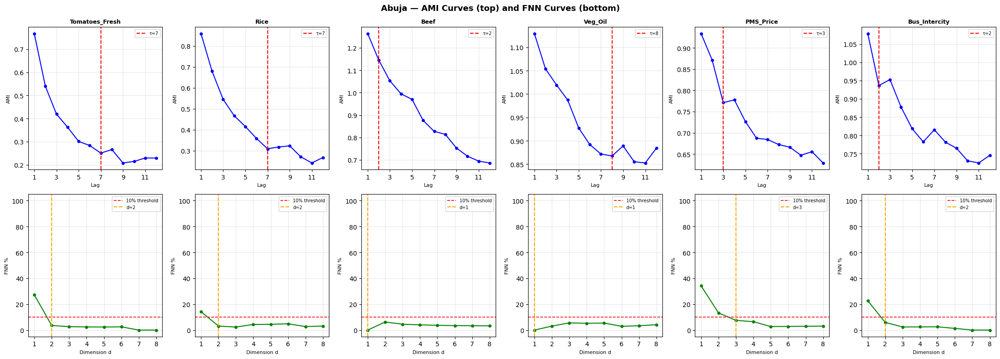

Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_AMI_FNN_Abuja.png


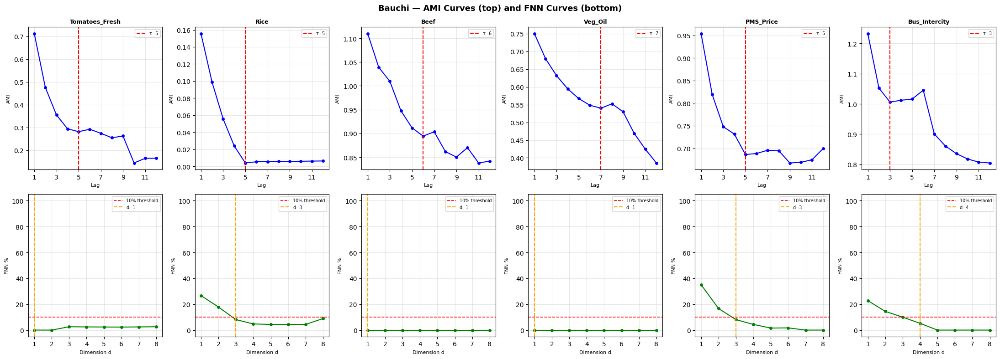

Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_AMI_FNN_Bauchi.png


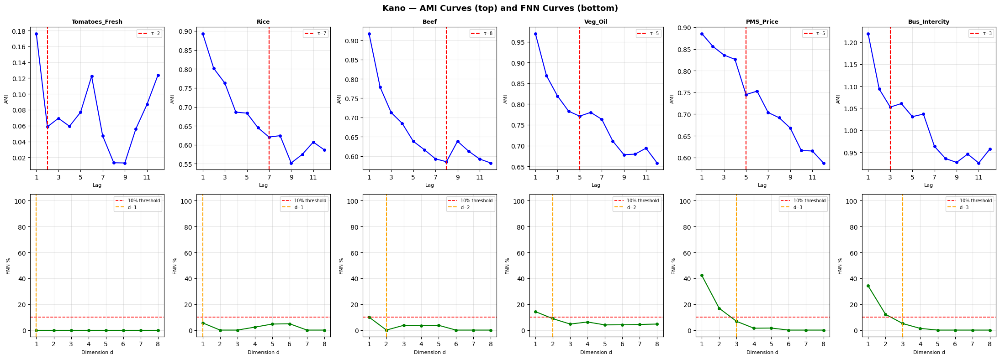

Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_AMI_FNN_Kano.png


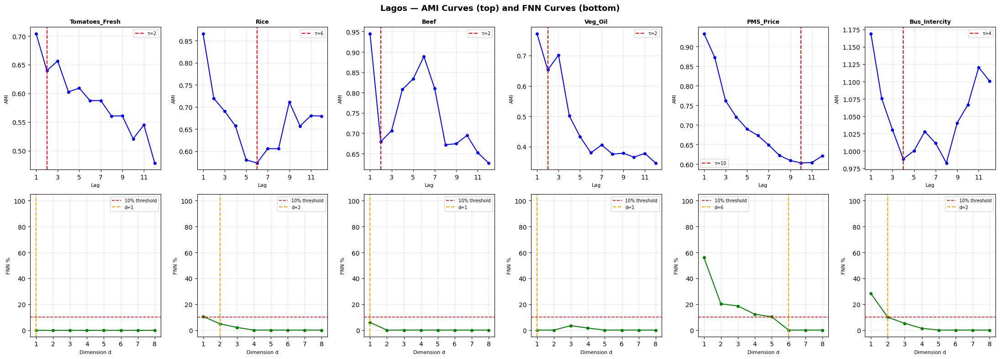

Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_AMI_FNN_Lagos.png


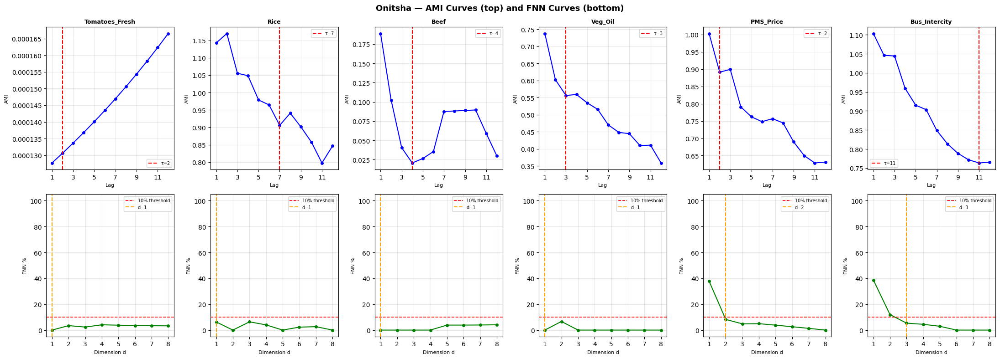

Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_AMI_FNN_Onitsha.png


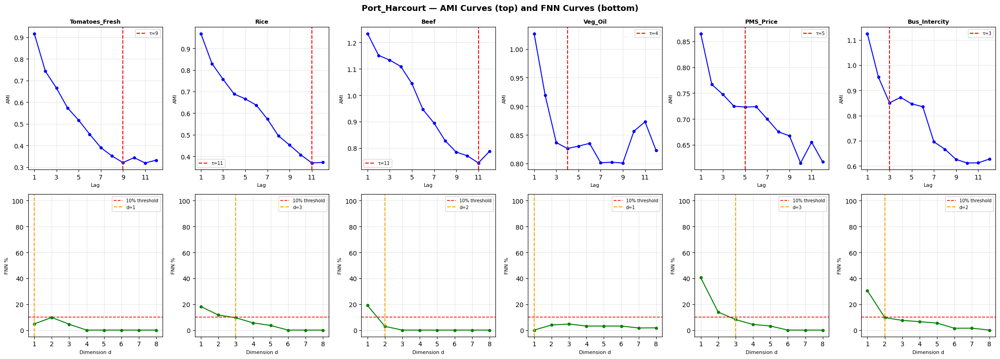

Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_AMI_FNN_Port_Harcourt.png


In [ ]:
# ============================================================
# CELL 5 — Visualise AMI and FNN for key indicators
# One figure per city showing all 14 city indicators
# ============================================================

KEY_INDICATORS = [
    'Tomatoes_Fresh', 'Rice', 'Beef', 'Veg_Oil',
    'PMS_Price', 'Bus_Intercity'
]

for city in CITIES:
    city_df = df[df['city'] == city].sort_values('date')

    fig, axes = plt.subplots(2, 6, figsize=(22, 8))
    fig.suptitle(
        f'{city} — AMI Curves (top) and FNN Curves (bottom)',
        fontsize=13, fontweight='bold'
    )

    for col_idx, indicator in enumerate(KEY_INDICATORS):
        if indicator not in city_df.columns:
            continue

        series = city_df[indicator].values
        valid  = series[~np.isnan(series)]
        if len(valid) < 20:
            continue

        city_params = params_df[
            (params_df['city'] == city) &
            (params_df['indicator'] == indicator)
        ]
        if len(city_params) == 0:
            continue

        tau = int(city_params['tau'].iloc[0])
        d   = int(city_params['d'].iloc[0])

        # AMI curve
        ami = average_mutual_information(series, max_lag=MAX_LAG)
        ax_ami = axes[0, col_idx]
        ax_ami.plot(range(1, MAX_LAG + 1), ami,
                    'b-o', markersize=4, linewidth=1.5)
        ax_ami.axvline(x=tau, color='red', linestyle='--',
                       linewidth=1.5, label=f'τ={tau}')
        ax_ami.set_title(indicator, fontsize=9, fontweight='bold')
        ax_ami.set_xlabel('Lag', fontsize=8)
        ax_ami.set_ylabel('AMI', fontsize=8)
        ax_ami.legend(fontsize=7)
        ax_ami.grid(True, alpha=0.3)
        ax_ami.set_xticks(range(1, MAX_LAG + 1, 2))

        # FNN curve
        fnn = false_nearest_neighbours(series, tau=tau, max_dim=MAX_DIM)
        ax_fnn = axes[1, col_idx]
        ax_fnn.plot(range(1, MAX_DIM + 1), fnn,
                    'g-o', markersize=4, linewidth=1.5)
        ax_fnn.axhline(y=10, color='red', linestyle='--',
                       linewidth=1.2, label='10% threshold')
        ax_fnn.axvline(x=d, color='orange', linestyle='--',
                       linewidth=1.5, label=f'd={d}')
        ax_fnn.set_xlabel('Dimension d', fontsize=8)
        ax_fnn.set_ylabel('FNN %', fontsize=8)
        ax_fnn.legend(fontsize=7)
        ax_fnn.grid(True, alpha=0.3)
        ax_fnn.set_ylim(-5, 105)
        ax_fnn.set_xticks(range(1, MAX_DIM + 1))

    plt.tight_layout()
    fname = DRIVE_PATH + f'S1_AMI_FNN_{city}.png'
    plt.savefig(fname, dpi=130, bbox_inches='tight')
    plt.show()
    print(f"Saved: {fname}")

In [ ]:
# ============================================================
# OUTLIER FIX — Run before Cell 6
# Fixes two confirmed data entry errors in Onitsha
# ============================================================

# Fix 1: Onitsha Red_Peppers January 2023
# Surrounding values: Dec 2022 = 1300, Feb 2023 = 1300
# Correct value: interpolated = 1300
mask1 = (
    (df['city'] == 'Onitsha') &
    (df['date'] == '2023-01-01')
)
df.loc[mask1, 'Red_Peppers'] = 1300.0
print(f"Fixed: Onitsha Red_Peppers 2023-01 → 1300")

# Fix 2: Onitsha Tinned_Tomatoes March 2024
# Surrounding values: Feb 2024 = 6000, Apr 2024 = 7500
# Correct value: interpolated midpoint = 6750
mask2 = (
    (df['city'] == 'Onitsha') &
    (df['date'] == '2024-03-01')
)
df.loc[mask2, 'Tinned_Tomatoes'] = 6750.0
print(f"Fixed: Onitsha Tinned_Tomatoes 2024-03 → 6750")

# Verify the fixes
onitsha_check = df[df['city'] == 'Onitsha'].sort_values('date')
print("\nOnitsha Red_Peppers 2022-12 to 2023-03:")
mask_check1 = (
    (onitsha_check['date'] >= '2022-12-01') &
    (onitsha_check['date'] <= '2023-03-01')
)
print(onitsha_check[mask_check1][['date','Red_Peppers']])

print("\nOnitsha Tinned_Tomatoes 2024-02 to 2024-04:")
mask_check2 = (
    (onitsha_check['date'] >= '2024-02-01') &
    (onitsha_check['date'] <= '2024-04-01')
)
print(onitsha_check[mask_check2][['date','Tinned_Tomatoes']])

# Save corrected master CSV back to Drive
df.to_csv(DRIVE_PATH + 'V3_Master_Wide.csv', index=False)
print("\nCorrected master CSV saved to Drive.")
print("Now re-run Cell 6 for clean phase portraits.")

Fixed: Onitsha Red_Peppers 2023-01 → 1300
Fixed: Onitsha Tinned_Tomatoes 2024-03 → 6750

Onitsha Red_Peppers 2022-12 to 2023-03:
          date  Red_Peppers
407 2022-12-01       1300.0
408 2023-01-01       1300.0
409 2023-02-01       1300.0
410 2023-03-01       2300.0

Onitsha Tinned_Tomatoes 2024-02 to 2024-04:
          date  Tinned_Tomatoes
421 2024-02-01           6000.0
422 2024-03-01           6750.0
423 2024-04-01           7500.0

Corrected master CSV saved to Drive.
Now re-run Cell 6 for clean phase portraits.


In [ ]:
# Fix Onitsha Salt February 2024
mask = (
    (df['city'] == 'Onitsha') &
    (df['date'] == '2024-02-01')
)
df.loc[mask, 'Salt'] = 500.0
print("Fixed: Onitsha Salt 2024-02 → 500")

# Save corrected master CSV
df.to_csv(DRIVE_PATH + 'V3_Master_Wide.csv', index=False)
print("Corrected master CSV saved. Stage 1 is now complete.")

Fixed: Onitsha Salt 2024-02 → 500
Corrected master CSV saved. Stage 1 is now complete.


Abuja — top 3 by variance: ['Beef', 'Bus_Intercity', 'Chicken']
Bauchi — top 3 by variance: ['Rice', 'Veg_Oil', 'Chicken']
Kano — top 3 by variance: ['Bus_Intercity', 'Chicken', 'Veg_Oil']
Lagos — top 3 by variance: ['Bus_Intercity', 'Beef', 'Chicken']
Onitsha — top 3 by variance: ['Curry', 'Tinned_Tomatoes', 'Bus_Intercity']
Port_Harcourt — top 3 by variance: ['Bus_Intercity', 'Beef', 'Red_Peppers']


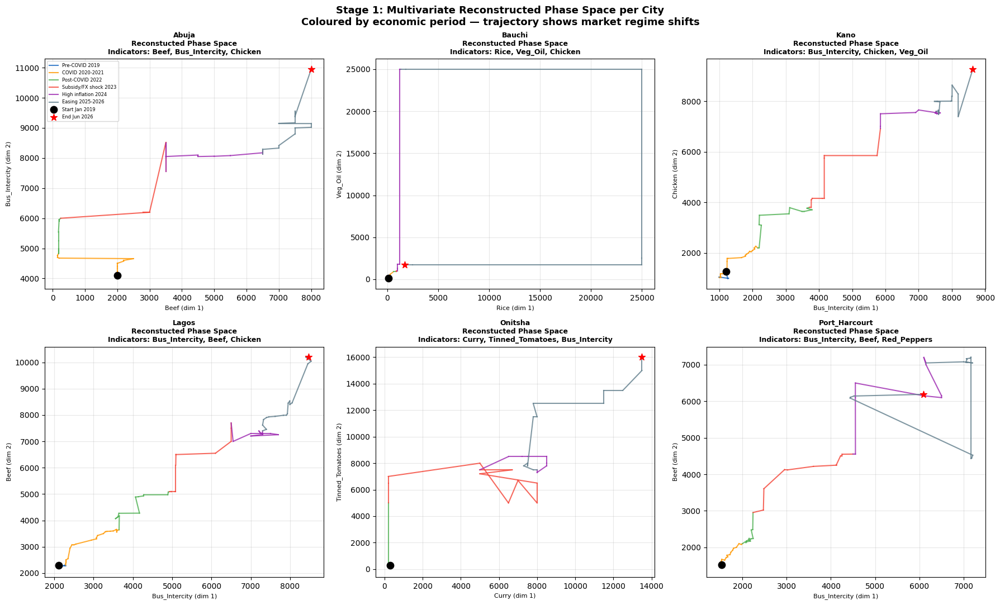


Saved: /content/drive/My Drive/Colab Notebooks/V3/S1_multivariate_phase_space.png


In [ ]:
# ============================================================
# CELL 6 — Multivariate reconstructed phase space per city
# Uses TOP 3 indicators by variance to build joint embedding
# Phase portrait coloured by economic period
# This is the reconstructed phase space Takens theorem guarantees
# ============================================================

PERIOD_COLORS = {
    'Pre-COVID 2019':         ('#1565C0', ('2019-01', '2019-12')),
    'COVID 2020-2021':        ('#FF9800', ('2020-01', '2021-12')),
    'Post-COVID 2022':        ('#4CAF50', ('2022-01', '2022-12')),
    'Subsidy/FX shock 2023':  ('#F44336', ('2023-01', '2023-12')),
    'High inflation 2024':    ('#9C27B0', ('2024-01', '2024-12')),
    'Easing 2025-2026':       ('#607D8B', ('2025-01', '2026-06')),
}


def get_period(date):
    """Return period label for a given date."""
    ds = date.strftime('%Y-%m')
    for label, (color, (start, end)) in PERIOD_COLORS.items():
        if start <= ds <= end:
            return label, color
    return 'Other', '#BDBDBD'


def build_multivariate_embedding(city_df, indicators, params_df, city):
    """
    Build multivariate reconstructed phase space.
    For each indicator, use its confirmed τ and d to create
    delay vectors. Concatenate all delay vectors horizontally.
    Returns the joint embedding matrix and date labels.
    """
    embeddings = []
    min_len    = np.inf

    for indicator in indicators:
        if indicator not in city_df.columns:
            continue

        row = params_df[
            (params_df['city'] == city) &
            (params_df['indicator'] == indicator)
        ]
        if len(row) == 0:
            continue

        tau    = int(row['tau'].iloc[0])
        d      = int(row['d'].iloc[0])
        series = city_df[indicator].values

        emb = build_delay_embedding(series, tau=tau, d=d)
        if emb.shape[0] > 1:
            embeddings.append(emb)
            min_len = min(min_len, emb.shape[0])

    if not embeddings or np.isinf(min_len):
        return None, None

    # Truncate all embeddings to same length and concatenate
    min_len  = int(min_len)
    joint    = np.concatenate(
        [e[:min_len] for e in embeddings], axis=1
    )
    dates    = city_df['date'].values[-min_len:]
    return joint, dates


fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for idx, city in enumerate(CITIES):
    city_df = df[df['city'] == city].sort_values('date')

    # Select top 3 indicators by variance for this city
    variances = {}
    for ind in CITY_INDICATORS:
        if ind in city_df.columns:
            v = city_df[ind].dropna().var()
            if v > 0:
                variances[ind] = v

    top3 = sorted(variances, key=variances.get, reverse=True)[:3]
    print(f"{city} — top 3 by variance: {top3}")

    joint, dates = build_multivariate_embedding(
        city_df, top3, params_df, city
    )

    ax = axes[idx]

    if joint is not None and joint.shape[1] >= 2:
        # 2D projection — first two dimensions of joint embedding
        x_coords = joint[:, 0]
        y_coords = joint[:, 1]

        # Plot trajectory segments coloured by economic period
        legend_added = set()
        for i in range(len(dates) - 1):
            date_val = pd.Timestamp(dates[i])
            label, color = get_period(date_val)

            ax.plot(
                [x_coords[i], x_coords[i + 1]],
                [y_coords[i], y_coords[i + 1]],
                color=color, linewidth=1.5, alpha=0.8,
                label=label if label not in legend_added else ''
            )
            legend_added.add(label)

        # Mark start and end
        ax.scatter(x_coords[0],  y_coords[0],
                   color='black', s=80, zorder=10,
                   marker='o', label='Start Jan 2019')
        ax.scatter(x_coords[-1], y_coords[-1],
                   color='red', s=80, zorder=10,
                   marker='*', label='End Jun 2026')

        ax.set_title(
            f'{city}\nReconstucted Phase Space\n'
            f'Indicators: {", ".join(top3)}',
            fontsize=9, fontweight='bold'
        )
        ax.set_xlabel(f'{top3[0]} (dim 1)', fontsize=8)
        ax.set_ylabel(f'{top3[1]} (dim 2)', fontsize=8)
        ax.grid(True, alpha=0.3)

        if idx == 0:
            ax.legend(fontsize=6, loc='upper left',
                      framealpha=0.8)

plt.suptitle(
    'Stage 1: Multivariate Reconstructed Phase Space per City\n'
    'Coloured by economic period — trajectory shows market regime shifts',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
fname = DRIVE_PATH + 'S1_multivariate_phase_space.png'
plt.savefig(fname, dpi=150, bbox_inches='tight')
plt.show()
print(f"\nSaved: {fname}")

In [ ]:
# ============================================================
# CELL 7 — Stage 1 Final Summary
# Everything needed to proceed to Stage 2
# ============================================================

params_df = pd.read_csv(DRIVE_PATH + 'S1_embedding_params_full.csv')

print("=" * 70)
print("STAGE 1 COMPLETE — TAKENS EMBEDDING")
print("=" * 70)

print("\n1. FULL PARAMETER TABLE (τ and d per indicator per city):")
print("-" * 70)
display_cols = ['city', 'indicator', 'level', 'tau', 'd', 'fnn_at_d', 'note']
display_df   = params_df[[c for c in display_cols if c in params_df.columns]]
print(display_df.to_string(index=False))

print("\n2. WHAT THESE VALUES FEED INTO DOWNSTREAM:")
print("-" * 70)
print()

for city in CITIES:
    cp = params_df[
        (params_df['city'] == city) &
        (params_df['level'] == 'city') &
        (params_df['note'] == 'ok')
    ]
    if len(cp) == 0:
        continue

    max_tau         = int(cp['tau'].max())
    max_d           = int(cp['d'].max())
    granger_max_lag = max_tau * max_d
    lstm_seq_len    = max_tau * (max_d - 1)
    lstm_hidden_min = max_d * 8
    n_state_vars    = max_d

    print(f"  {city}")
    print(f"    Stage 2 Granger:  test up to lag {granger_max_lag} months")
    print(f"    VAR lag order:    {granger_max_lag} months")
    print(f"    Mesa obs vector:  >= {n_state_vars} state variables")
    print(f"    LSTM seq length:  {lstm_seq_len} months look-back")
    print(f"    LSTM hidden min:  {lstm_hidden_min} units")
    print()

nat = params_df[params_df['level'] == 'national']
if len(nat) > 0:
    print("  National indicators (USD_NGN, CBN_MPR):")
    for _, row in nat.iterrows():
        print(f"    {row['indicator']:<12} "
              f"τ={row['tau']}  d={row['d']}")
    print()

print("3. FILES SAVED TO DRIVE:")
print("-" * 70)
for fname in [
    'S1_embedding_params_raw.csv',
    'S1_embedding_params_full.csv',
    'S1_tau_table.csv',
    'S1_d_table.csv',
    'S1_multivariate_phase_space.png',
]:
    print(f"   {DRIVE_PATH}{fname}")

print()
print("NEXT STEP: Stage 2 — Granger Causality")
print("  Load: S1_embedding_params_full.csv")
print("  Use:  tau and d values to set Granger test lag orders")
print("  Test: all indicator pairs per city + cross-city transmission")

STAGE 1 COMPLETE — TAKENS EMBEDDING

1. FULL PARAMETER TABLE (τ and d per indicator per city):
----------------------------------------------------------------------
         city       indicator    level  tau  d  fnn_at_d note
        Abuja            Rice     city    7  2      3.12   ok
        Abuja            Salt     city    2  1      0.00   ok
        Abuja       Seasoning     city    5  1      5.56   ok
        Abuja           Curry     city    6  2      0.00   ok
        Abuja           Thyme     city   11  1      0.00   ok
        Abuja     Red_Peppers     city    4  1      0.00   ok
        Abuja  Tomatoes_Fresh     city    7  2      3.57   ok
        Abuja         Veg_Oil     city    8  1      0.00   ok
        Abuja Tinned_Tomatoes     city    6  2      6.67   ok
        Abuja            Beef     city    2  1      0.00   ok
        Abuja         Chicken     city    7  1      5.56   ok
        Abuja          Onions     city    5  1      0.00   ok
        Abuja       PMS_Pric

In [ ]:
# Check for suspicious values in Bauchi Veg_Oil
bauchi = df[df['city'] == 'Bauchi'].sort_values('date')
print(bauchi[['date', 'Veg_Oil']].to_string())

# Check Onitsha
onitsha = df[df['city'] == 'Onitsha'].sort_values('date')
print(onitsha[['date', 'Tinned_Tomatoes', 'Red_Peppers']].to_string())

          date  Veg_Oil
90  2019-01-01   1100.0
91  2019-02-01   1100.0
92  2019-03-01   1100.0
93  2019-04-01   1100.0
94  2019-05-01   1100.0
95  2019-06-01   1100.0
96  2019-07-01   1100.0
97  2019-08-01   1100.0
98  2019-09-01   1100.0
99  2019-10-01   1200.0
100 2019-11-01   1250.0
101 2019-12-01   1250.0
102 2020-01-01   1250.0
103 2020-02-01   1250.0
104 2020-03-01   1250.0
105 2020-04-01   1350.0
106 2020-05-01   1350.0
107 2020-06-01   1350.0
108 2020-07-01   1350.0
109 2020-08-01   1350.0
110 2020-09-01   1350.0
111 2020-10-01   1350.0
112 2020-11-01   1350.0
113 2020-12-01   1350.0
114 2021-01-01   1350.0
115 2021-02-01   1350.0
116 2021-03-01   1350.0
117 2021-04-01   1350.0
118 2021-05-01   1350.0
119 2021-06-01   1350.0
120 2021-07-01   1350.0
121 2021-08-01   1350.0
122 2021-09-01   1350.0
123 2021-10-01   1350.0
124 2021-11-01   1350.0
125 2021-12-01   1350.0
126 2022-01-01   1350.0
127 2022-02-01   1350.0
128 2022-03-01   1350.0
129 2022-04-01   1350.0
130 2022-05-01  

In [ ]:
onitsha = df[df['city'] == 'Onitsha'].sort_values('date')
print(onitsha[['date', 'Salt']].to_string())

          date      Salt
360 2019-01-01     100.0
361 2019-02-01     100.0
362 2019-03-01     100.0
363 2019-04-01     100.0
364 2019-05-01     100.0
365 2019-06-01     100.0
366 2019-07-01     100.0
367 2019-08-01     100.0
368 2019-09-01     100.0
369 2019-10-01     100.0
370 2019-11-01     100.0
371 2019-12-01     100.0
372 2020-01-01     100.0
373 2020-02-01     100.0
374 2020-03-01     100.0
375 2020-04-01     100.0
376 2020-05-01     100.0
377 2020-06-01     100.0
378 2020-07-01     100.0
379 2020-08-01     100.0
380 2020-09-01     100.0
381 2020-10-01     100.0
382 2020-11-01     100.0
383 2020-12-01     100.0
384 2021-01-01     100.0
385 2021-02-01     100.0
386 2021-03-01     100.0
387 2021-04-01     100.0
388 2021-05-01     100.0
389 2021-06-01     100.0
390 2021-07-01     200.0
391 2021-08-01     200.0
392 2021-09-01     500.0
393 2021-10-01     500.0
394 2021-11-01     300.0
395 2021-12-01     300.0
396 2022-01-01     300.0
397 2022-02-01     300.0
398 2022-03-01     300.0


In [ ]:
# ============================================================
# STAGE 2 — GRANGER CAUSALITY
# V3 Nigeria Food Price Intelligence
# Flows directly from Stage 1 Takens Embedding outputs
# Uses S1_embedding_params_full.csv for lag orders
# Uniform first-difference transformation throughout
# ============================================================

# CELL 1 — Load libraries and all Stage 1 outputs
# ============================================================
!pip install statsmodels -q

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import json
import pickle
from statsmodels.tsa.stattools import grangercausalitytests, adfuller
warnings.filterwarnings('ignore')

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'

# Load master CSV (corrected, outliers fixed)
df = pd.read_csv(
    DRIVE_PATH + 'V3_Master_Wide.csv',
    parse_dates=['date']
)
df = df.sort_values(['city', 'date']).reset_index(drop=True)

# Load Stage 1 embedding parameters
params = pd.read_csv(DRIVE_PATH + 'S1_embedding_params_full.csv')

CITIES = sorted(df['city'].unique())

CITY_INDICATORS = [
    'Rice', 'Salt', 'Seasoning', 'Curry', 'Thyme',
    'Red_Peppers', 'Tomatoes_Fresh', 'Veg_Oil',
    'Tinned_Tomatoes', 'Beef', 'Chicken', 'Onions',
    'PMS_Price', 'Bus_Intercity'
]
NATIONAL_INDICATORS = ['USD_NGN', 'CBN_MPR']
ALL_INDICATORS      = CITY_INDICATORS + NATIONAL_INDICATORS

GRANGER_MAX_LAG = 12
P_THRESHOLD     = 0.05

print(f"Master CSV loaded: {df.shape}")
print(f"Cities: {CITIES}")
print(f"Stage 1 params loaded: {params.shape}")
print(f"Indicators per city: {len(CITY_INDICATORS)}")
print(f"National indicators: {len(NATIONAL_INDICATORS)}")
print(f"Granger max lag cap: {GRANGER_MAX_LAG} months")
print(f"P-value threshold:   {P_THRESHOLD}")

# Quick data check
print("\nSample — Lagos first 5 rows:")
lagos_sample = df[df['city'] == 'Lagos'].head(5)
print(lagos_sample[['date','Tomatoes_Fresh',
                     'PMS_Price','Bus_Intercity',
                     'USD_NGN','CBN_MPR']].to_string())

Mounted at /content/drive
Master CSV loaded: (540, 18)
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Stage 1 params loaded: (86, 8)
Indicators per city: 14
National indicators: 2
Granger max lag cap: 12 months
P-value threshold:   0.05

Sample — Lagos first 5 rows:
          date  Tomatoes_Fresh   PMS_Price  Bus_Intercity  USD_NGN  CBN_MPR
270 2019-01-01           100.0  144.866667    2105.555556   306.25     14.0
271 2019-02-01           150.0  144.875000    2082.352941   306.35     14.0
272 2019-03-01           150.0  145.000000    2127.619048   306.45     13.5
273 2019-04-01           100.0  145.000000    2200.000000   306.40     13.5
274 2019-05-01           100.0  144.904762    2290.000000   306.45     13.5


In [ ]:
# ============================================================
# CELL 2 — Core helper functions
# ============================================================

def prepare_series(series):
    """
    Uniform first-difference transformation.
    Produces month-on-month price change in NGN.
    All indicators on same scale — comparable for Granger.
    Forward-fill gaps before differencing.
    """
    clean = series.copy().ffill().bfill()
    return clean.diff().dropna()


def get_granger_lag(city, indicator, params, cap=GRANGER_MAX_LAG):
    """
    Get Granger test lag from Stage 1 τ value.
    Uses τ of the CAUSE variable.
    Capped at GRANGER_MAX_LAG for statistical power.
    """
    city_key = city if indicator in CITY_INDICATORS else 'National'
    mask = (
        (params['city'] == city_key) &
        (params['indicator'] == indicator)
    )
    row = params[mask]
    if len(row) == 0:
        return min(3, cap)
    tau = int(row['tau'].iloc[0])
    return min(tau, cap)


def run_granger(x_series, y_series, max_lag):
    """
    Test whether x Granger-causes y.
    Returns: p_value, optimal_lag, significant
    """
    try:
        combined = pd.concat(
            [y_series, x_series], axis=1
        ).dropna()
        combined.columns = ['y', 'x']

        # Need sufficient observations
        if len(combined) < max_lag * 3 + 10:
            return 1.0, 1, False

        # Skip if either series is constant
        if combined['x'].std() < 1e-8 or combined['y'].std() < 1e-8:
            return 1.0, 1, False

        result = grangercausalitytests(
            combined[['y', 'x']],
            maxlag=max_lag
        )

        pvals = [
            result[lag][0]['ssr_ftest'][1]
            for lag in range(1, max_lag + 1)
        ]
        min_pval    = min(pvals)
        optimal_lag = pvals.index(min_pval) + 1
        significant = min_pval < P_THRESHOLD

        return round(min_pval, 4), optimal_lag, significant

    except Exception:
        return 1.0, 1, False


print("Helper functions defined.")
print("Transformation: uniform first difference (NGN per month)")

Helper functions defined.
Transformation: uniform first difference (NGN per month)


In [ ]:
# ============================================================
# CELL 3 — Stationarity confirmation
# Verify first difference produces stationary series
# Required assumption for valid Granger tests
# ============================================================

print("Confirming stationarity after first differencing...")
print("=" * 65)

stationarity_rows = []

for city in CITIES:
    city_df = df[df['city'] == city].sort_values('date')
    n_pass  = 0
    n_fail  = 0

    for indicator in ALL_INDICATORS:
        if indicator not in city_df.columns:
            continue

        diff_series = prepare_series(city_df[indicator])
        clean       = diff_series.dropna()

        if len(clean) < 15:
            continue

        try:
            pval       = adfuller(clean, autolag='AIC')[1]
            is_stat    = pval < 0.05
        except Exception:
            pval       = 1.0
            is_stat    = False

        if is_stat:
            n_pass += 1
        else:
            n_fail += 1

        stationarity_rows.append({
            'city':       city,
            'indicator':  indicator,
            'adf_pval':   round(pval, 4),
            'stationary': is_stat
        })

    print(f"  {city:<15} pass={n_pass}  fail={n_fail}")

stat_df = pd.DataFrame(stationarity_rows)
stat_df.to_csv(DRIVE_PATH + 'S2_stationarity.csv', index=False)

total_pass = stat_df['stationary'].sum()
total_fail = (~stat_df['stationary']).sum()
print(f"\nTotal stationary after differencing: {total_pass}")
print(f"Total still non-stationary:          {total_fail}")

if total_fail > 0:
    print("\nNon-stationary series (will still be tested):")
    fails = stat_df[~stat_df['stationary']]
    print(fails[['city','indicator','adf_pval']].to_string())
else:
    print("\nAll series stationary. Ready for Granger testing.")

print(f"\nSaved: {DRIVE_PATH}S2_stationarity.csv")

Confirming stationarity after first differencing...
  Abuja           pass=15  fail=1
  Bauchi          pass=13  fail=3
  Kano            pass=14  fail=2
  Lagos           pass=13  fail=3
  Onitsha         pass=15  fail=1
  Port_Harcourt   pass=13  fail=3

Total stationary after differencing: 83
Total still non-stationary:          13

Non-stationary series (will still be tested):
             city    indicator  adf_pval
14          Abuja      USD_NGN    0.4122
18         Bauchi    Seasoning    0.2039
21         Bauchi  Red_Peppers    0.7725
30         Bauchi      USD_NGN    0.4122
42           Kano      Chicken    0.2688
46           Kano      USD_NGN    0.4122
53          Lagos  Red_Peppers    0.2250
59          Lagos       Onions    0.1986
62          Lagos      USD_NGN    0.4122
78        Onitsha      USD_NGN    0.4122
81  Port_Harcourt         Salt    0.0808
83  Port_Harcourt        Curry    0.6738
94  Port_Harcourt      USD_NGN    0.4122

Saved: /content/drive/My Drive/Colab Note

In [ ]:
# ============================================================
# CELL 4 — Sanity check before full run
# Manual test: PMS → Tomatoes_Fresh in Lagos
# Confirms the pipeline produces real F-statistics
# ============================================================

print("SANITY CHECK — PMS → Tomatoes_Fresh in Lagos")
print("=" * 65)

lagos_df = (df[df['city'] == 'Lagos']
            .sort_values('date')
            .set_index('date'))

pms_diff = prepare_series(lagos_df['PMS_Price'])
tom_diff = prepare_series(lagos_df['Tomatoes_Fresh'])
bus_diff = prepare_series(lagos_df['Bus_Intercity'])

combined = pd.concat([tom_diff, pms_diff], axis=1).dropna()
combined.columns = ['tomato', 'pms']

print(f"Series length: {len(combined)}")
print(f"Tomato diff — mean={combined['tomato'].mean():.2f}  "
      f"std={combined['tomato'].std():.2f}")
print(f"PMS diff    — mean={combined['pms'].mean():.2f}  "
      f"std={combined['pms'].std():.2f}")
print(f"Correlation: {combined.corr().iloc[0,1]:.4f}")

print(f"\nGranger test PMS → Tomatoes_Fresh (maxlag=4):")
print(f"{'Lag':<6} {'F-stat':<12} {'p-value':<12} {'Significant'}")
print("-" * 45)

result = grangercausalitytests(combined[['tomato','pms']], maxlag=4)
for lag in range(1, 5):
    fstat = result[lag][0]['ssr_ftest'][0]
    pval  = result[lag][0]['ssr_ftest'][1]
    sig   = '✓ YES' if pval < P_THRESHOLD else 'no'
    print(f"{lag:<6} {fstat:<12.4f} {pval:<12.4f} {sig}")

print(f"\nGranger test Bus_Intercity → Tomatoes_Fresh (maxlag=4):")
combined2 = pd.concat([tom_diff, bus_diff], axis=1).dropna()
combined2.columns = ['tomato', 'bus']
print(f"{'Lag':<6} {'F-stat':<12} {'p-value':<12} {'Significant'}")
print("-" * 45)

result2 = grangercausalitytests(combined2[['tomato','bus']], maxlag=4)
for lag in range(1, 5):
    fstat = result2[lag][0]['ssr_ftest'][0]
    pval  = result2[lag][0]['ssr_ftest'][1]
    sig   = '✓ YES' if pval < P_THRESHOLD else 'no'
    print(f"{lag:<6} {fstat:<12.4f} {pval:<12.4f} {sig}")

print("\nIf F-statistics above are non-zero the pipeline is working.")
print("Proceed to Cell 5 for full within-city tests.")

SANITY CHECK — PMS → Tomatoes_Fresh in Lagos
Series length: 89
Tomato diff — mean=15.73  std=133.91
PMS diff    — mean=15.91  std=66.38
Correlation: 0.0086

Granger test PMS → Tomatoes_Fresh (maxlag=4):
Lag    F-stat       p-value      Significant
---------------------------------------------
1      0.0595       0.8078       no
2      8.0402       0.0006       ✓ YES
3      5.3871       0.0020       ✓ YES
4      4.4043       0.0030       ✓ YES

Granger test Bus_Intercity → Tomatoes_Fresh (maxlag=4):
Lag    F-stat       p-value      Significant
---------------------------------------------
1      0.2702       0.6045       no
2      0.2138       0.8080       no
3      3.0818       0.0321       ✓ YES
4      2.2424       0.0723       no

If F-statistics above are non-zero the pipeline is working.
Proceed to Cell 5 for full within-city tests.


In [ ]:
# ============================================================
# CELL 5 — Full within-city Granger causality tests
# All ordered pairs per city
# Lag order from Stage 1 τ values (capped at 12)
# ============================================================

print("Running within-city Granger causality tests...")
print(f"Testing {len(ALL_INDICATORS)**2 - len(ALL_INDICATORS)} "
      f"pairs per city × {len(CITIES)} cities")
print("=" * 65)

within_city_results = []

for city in CITIES:
    city_df = (df[df['city'] == city]
               .sort_values('date')
               .set_index('date'))

    print(f"\n{city}:")
    n_sig = 0

    # Pre-compute all transformed series for efficiency
    transformed = {}
    for ind in ALL_INDICATORS:
        if ind in city_df.columns:
            transformed[ind] = prepare_series(city_df[ind])

    for x_ind in ALL_INDICATORS:
        if x_ind not in transformed:
            continue

        x_series = transformed[x_ind]
        max_lag  = get_granger_lag(city, x_ind, params)

        for y_ind in ALL_INDICATORS:
            if y_ind == x_ind:
                continue
            if y_ind not in transformed:
                continue

            y_series = transformed[y_ind]

            pval, opt_lag, sig = run_granger(
                x_series, y_series, max_lag
            )

            within_city_results.append({
                'city':        city,
                'cause':       x_ind,
                'effect':      y_ind,
                'p_value':     pval,
                'optimal_lag': opt_lag,
                'significant': sig,
                'direction':   f'{x_ind} → {y_ind}'
            })

            if sig:
                n_sig += 1
                print(f"  ✓ {x_ind:<22} → {y_ind:<22} "
                      f"p={pval:.4f}  lag={opt_lag}")

    print(f"  Significant pairs: {n_sig}")

granger_within = pd.DataFrame(within_city_results)
granger_within.to_csv(
    DRIVE_PATH + 'S2_granger_within_city.csv', index=False
)

print(f"\nTotal pairs tested:  {len(granger_within)}")
print(f"Total significant:   {granger_within['significant'].sum()}")
print(f"P-value distribution:")
print(granger_within['p_value'].describe())
print(f"\nSaved: {DRIVE_PATH}S2_granger_within_city.csv")

Running within-city Granger causality tests...
Testing 240 pairs per city × 6 cities

Abuja:
  ✓ Rice                   → Veg_Oil                p=0.0382  lag=5
  ✓ Rice                   → Onions                 p=0.0241  lag=2
  ✓ Rice                   → PMS_Price              p=0.0207  lag=3
  ✓ Rice                   → Bus_Intercity          p=0.0068  lag=6
  ✓ Rice                   → CBN_MPR                p=0.0355  lag=1
  ✓ Seasoning              → Tomatoes_Fresh         p=0.0308  lag=3
  ✓ Seasoning              → Veg_Oil                p=0.0469  lag=5
  ✓ Seasoning              → PMS_Price              p=0.0112  lag=5
  ✓ Seasoning              → Bus_Intercity          p=0.0002  lag=5
  ✓ Curry                  → Salt                   p=0.0293  lag=4
  ✓ Curry                  → Tinned_Tomatoes        p=0.0477  lag=4
  ✓ Curry                  → Onions                 p=0.0139  lag=1
  ✓ Curry                  → PMS_Price              p=0.0215  lag=5
  ✓ Curry              

In [ ]:
# ============================================================
# CELL 6 — Cross-city Granger causality
# Price transmission between cities per commodity
# Becomes NetworkX edge weight matrix in Layer 2
# ============================================================

print("Running cross-city Granger causality tests...")
print("=" * 65)

cross_city_results = []

for indicator in CITY_INDICATORS:
    n_sig_indicator = 0

    for city1 in CITIES:
        df1 = (df[df['city'] == city1]
               .sort_values('date')
               .set_index('date'))

        if indicator not in df1.columns:
            continue

        x_series = prepare_series(df1[indicator])

        for city2 in CITIES:
            if city1 == city2:
                continue

            df2 = (df[df['city'] == city2]
                   .sort_values('date')
                   .set_index('date'))

            if indicator not in df2.columns:
                continue

            y_series = prepare_series(df2[indicator])

            lag1    = get_granger_lag(city1, indicator, params)
            lag2    = get_granger_lag(city2, indicator, params)
            max_lag = min(max(lag1, lag2), GRANGER_MAX_LAG)

            pval, opt_lag, sig = run_granger(
                x_series, y_series, max_lag
            )

            cross_city_results.append({
                'indicator':   indicator,
                'cause_city':  city1,
                'effect_city': city2,
                'p_value':     pval,
                'optimal_lag': opt_lag,
                'significant': sig,
                'direction':   f'{city1} → {city2}'
            })

            if sig:
                n_sig_indicator += 1
                print(f"  {indicator:<20} "
                      f"{city1:<15} → {city2:<15} "
                      f"p={pval:.4f}  lag={opt_lag}")

    if n_sig_indicator == 0:
        print(f"  {indicator:<20} "
              f"no significant cross-city transmission found")

granger_cross = pd.DataFrame(cross_city_results)
granger_cross.to_csv(
    DRIVE_PATH + 'S2_granger_cross_city.csv', index=False
)

print(f"\nTotal cross-city pairs tested: {len(granger_cross)}")
print(f"Significant:                   {granger_cross['significant'].sum()}")
print(f"\nSaved: {DRIVE_PATH}S2_granger_cross_city.csv")

Running cross-city Granger causality tests...
  Rice                 Abuja           → Bauchi          p=0.0359  lag=7
  Rice                 Bauchi          → Abuja           p=0.0000  lag=1
  Rice                 Kano            → Bauchi          p=0.0127  lag=6
  Rice                 Kano            → Lagos           p=0.0161  lag=3
  Rice                 Kano            → Onitsha         p=0.0324  lag=4
  Rice                 Kano            → Port_Harcourt   p=0.0173  lag=9
  Rice                 Lagos           → Bauchi          p=0.0000  lag=6
  Rice                 Lagos           → Kano            p=0.0002  lag=2
  Rice                 Port_Harcourt   → Bauchi          p=0.0000  lag=9
  Rice                 Port_Harcourt   → Kano            p=0.0050  lag=1
  Rice                 Port_Harcourt   → Lagos           p=0.0000  lag=3
  Rice                 Port_Harcourt   → Onitsha         p=0.0295  lag=4
  Salt                 Abuja           → Kano            p=0.0007  lag=4
  Sal

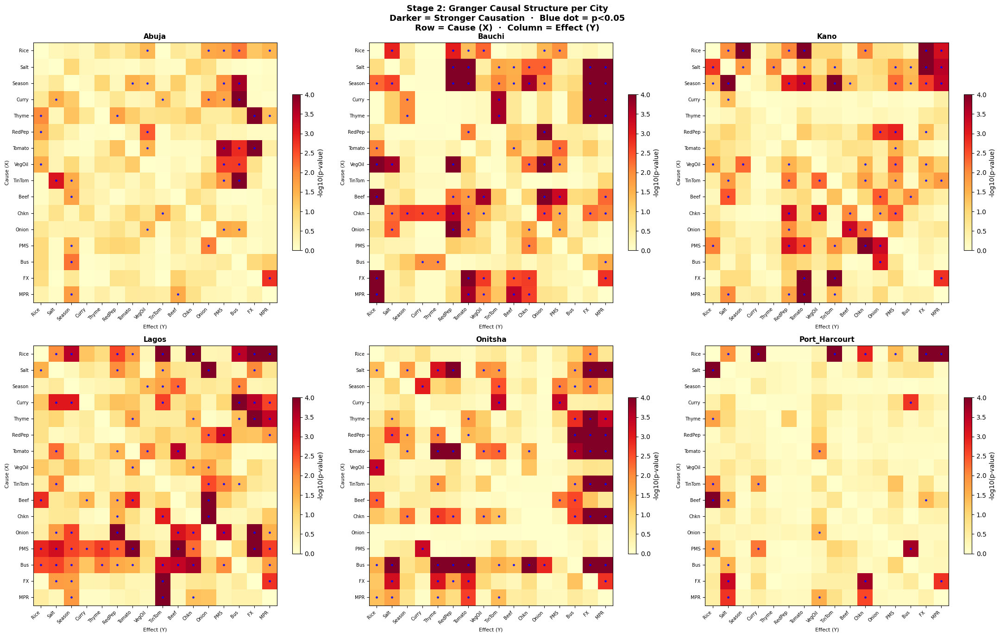

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2_granger_heatmaps.png


In [ ]:
# ============================================================
# CELL 7 — Granger causal structure heatmaps per city
# ============================================================

SHORT = {
    'Rice':'Rice','Salt':'Salt','Seasoning':'Season',
    'Curry':'Curry','Thyme':'Thyme','Red_Peppers':'RedPep',
    'Tomatoes_Fresh':'Tomato','Veg_Oil':'VegOil',
    'Tinned_Tomatoes':'TinTom','Beef':'Beef',
    'Chicken':'Chkn','Onions':'Onion',
    'PMS_Price':'PMS','Bus_Intercity':'Bus',
    'USD_NGN':'FX','CBN_MPR':'MPR'
}

all_inds   = ALL_INDICATORS
short_inds = [SHORT.get(i, i) for i in all_inds]
n          = len(all_inds)

fig, axes = plt.subplots(2, 3, figsize=(22, 14))
axes = axes.flatten()

for idx, city in enumerate(CITIES):
    city_data    = granger_within[granger_within['city'] == city]
    pval_matrix  = np.ones((n, n))

    for _, row in city_data.iterrows():
        if row['cause'] in all_inds and row['effect'] in all_inds:
            i = all_inds.index(row['cause'])
            j = all_inds.index(row['effect'])
            pval_matrix[i, j] = row['p_value']

    log_pval = -np.log10(pval_matrix + 1e-10)
    np.fill_diagonal(log_pval, 0)

    ax = axes[idx]
    im = ax.imshow(log_pval, cmap='YlOrRd',
                   aspect='auto', vmin=0, vmax=4)

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(short_inds, rotation=45,
                       ha='right', fontsize=7)
    ax.set_yticklabels(short_inds, fontsize=7)
    ax.set_title(f'{city}', fontweight='bold', fontsize=11)
    ax.set_xlabel('Effect (Y)', fontsize=8)
    ax.set_ylabel('Cause (X)', fontsize=8)

    for i in range(n):
        for j in range(n):
            if pval_matrix[i, j] < P_THRESHOLD and i != j:
                ax.plot(j, i, 'b.', markersize=5, alpha=0.8)

    plt.colorbar(im, ax=ax, shrink=0.6,
                 label='-log10(p-value)')

plt.suptitle(
    'Stage 2: Granger Causal Structure per City\n'
    'Darker = Stronger Causation  ·  Blue dot = p<0.05\n'
    'Row = Cause (X)  ·  Column = Effect (Y)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
fname = DRIVE_PATH + 'S2_granger_heatmaps.png'
plt.savefig(fname, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved: {fname}")

In [ ]:
# ============================================================
# CELL 8 — Stage 2 Summary
# Confirmed causal variables per city
# These feed directly into Stage 2b VAR regression
# ============================================================

print("=" * 65)
print("STAGE 2 COMPLETE — CONFIRMED CAUSAL VARIABLES PER CITY")
print("=" * 65)

confirmed_causes = {}

for city in CITIES:
    city_data = granger_within[
        (granger_within['city'] == city) &
        (granger_within['significant'] == True)
    ]

    tomato_causes = city_data[
        city_data['effect'] == 'Tomatoes_Fresh'
    ]['cause'].tolist()

    pms_effects = city_data[
        city_data['cause'] == 'PMS_Price'
    ]['effect'].tolist()

    bus_effects = city_data[
        city_data['cause'] == 'Bus_Intercity'
    ]['effect'].tolist()

    bus_causes = city_data[
        city_data['effect'] == 'Bus_Intercity'
    ]['cause'].tolist()

    all_causal_vars = sorted(list(set(
        city_data['cause'].tolist() +
        city_data['effect'].tolist()
    )))

    confirmed_causes[city] = {
        'tomato_causes':   tomato_causes,
        'pms_effects':     pms_effects,
        'bus_effects':     bus_effects,
        'bus_causes':      bus_causes,
        'all_causal_vars': all_causal_vars,
        'n_significant':   len(city_data)
    }

    d_required = int(params[
        (params['city'] == city) &
        (params['note'] == 'ok')
    ]['d'].max())

    print(f"\n{city} (Takens d={d_required}):")
    print(f"  Significant pairs:        {len(city_data)}")
    print(f"  Causes of Tomatoes_Fresh: {tomato_causes}")
    print(f"  PMS_Price causes:         {pms_effects}")
    print(f"  Bus_Intercity causes:     {bus_effects}")
    print(f"  Bus_Intercity caused by:  {bus_causes}")
    print(f"  All causal variables:     {all_causal_vars}")

    status = '✓' if len(all_causal_vars) >= d_required else '⚠'
    print(f"  {status} {len(all_causal_vars)} causal vars "
          f"vs {d_required} required by Takens")

with open(DRIVE_PATH + 'S2_confirmed_causes.json', 'w') as f:
    json.dump(confirmed_causes, f, indent=2)

print(f"\nFiles saved to Drive:")
for fname in [
    'S2_stationarity.csv',
    'S2_granger_within_city.csv',
    'S2_granger_cross_city.csv',
    'S2_granger_heatmaps.png',
    'S2_confirmed_causes.json',
]:
    print(f"  {DRIVE_PATH}{fname}")

print(f"\nNEXT STEP: Stage 2b — VAR Regression")
print(f"  Reads: S2_confirmed_causes.json")
print(f"  Produces: VAR coefficient matrix per city")
print(f"  Output: CTDE initialisation weights for Mesa agents")

STAGE 2 COMPLETE — CONFIRMED CAUSAL VARIABLES PER CITY

Abuja (Takens d=3):
  Significant pairs:        42
  Causes of Tomatoes_Fresh: ['Seasoning']
  PMS_Price causes:         ['Seasoning', 'Onions']
  Bus_Intercity causes:     ['Seasoning']
  Bus_Intercity caused by:  ['Rice', 'Seasoning', 'Curry', 'Tomatoes_Fresh', 'Veg_Oil', 'Tinned_Tomatoes', 'Onions']
  All causal variables:     ['Beef', 'Bus_Intercity', 'CBN_MPR', 'Chicken', 'Curry', 'Onions', 'PMS_Price', 'Red_Peppers', 'Rice', 'Salt', 'Seasoning', 'Thyme', 'Tinned_Tomatoes', 'Tomatoes_Fresh', 'USD_NGN', 'Veg_Oil']
  ✓ 16 causal vars vs 3 required by Takens

Bauchi (Takens d=4):
  Significant pairs:        81
  Causes of Tomatoes_Fresh: ['Rice', 'Salt', 'Seasoning', 'Red_Peppers', 'Beef', 'Chicken', 'Onions', 'USD_NGN', 'CBN_MPR']
  PMS_Price causes:         ['Chicken']
  Bus_Intercity causes:     ['Curry', 'Thyme', 'CBN_MPR']
  Bus_Intercity caused by:  []
  All causal variables:     ['Beef', 'Bus_Intercity', 'CBN_MPR', 'Chick

In [ ]:
# Quick cross-city summary
cross = pd.read_csv(DRIVE_PATH + 'S2_granger_cross_city.csv')
sig_cross = cross[cross['significant'] == True]
print(f"Total significant cross-city pairs: {len(sig_cross)}")
print(f"\nBy indicator:")
print(sig_cross.groupby('indicator').size().sort_values(ascending=False))
print(f"\nSignificant cross-city pairs for key indicators:")
for ind in ['Tomatoes_Fresh','Rice','Beef','PMS_Price','Bus_Intercity']:
    pairs = sig_cross[sig_cross['indicator'] == ind]
    if len(pairs) > 0:
        print(f"\n  {ind}:")
        for _, row in pairs.iterrows():
            print(f"    {row['cause_city']:<15} → {row['effect_city']:<15} "
                  f"p={row['p_value']:.4f}  lag={row['optimal_lag']}")

Total significant cross-city pairs: 122

By indicator:
indicator
PMS_Price          19
Rice               12
Tinned_Tomatoes    12
Salt               10
Seasoning           9
Chicken             9
Thyme               8
Beef                8
Veg_Oil             7
Tomatoes_Fresh      7
Curry               6
Red_Peppers         6
Bus_Intercity       5
Onions              4
dtype: int64

Significant cross-city pairs for key indicators:

  Tomatoes_Fresh:
    Abuja           → Onitsha         p=0.0335  lag=7
    Bauchi          → Abuja           p=0.0452  lag=1
    Bauchi          → Kano            p=0.0341  lag=1
    Bauchi          → Lagos           p=0.0015  lag=4
    Bauchi          → Port_Harcourt   p=0.0414  lag=1
    Kano            → Bauchi          p=0.0000  lag=1
    Onitsha         → Bauchi          p=0.0000  lag=5

  Rice:
    Abuja           → Bauchi          p=0.0359  lag=7
    Bauchi          → Abuja           p=0.0000  lag=1
    Kano            → Bauchi          p=0.0127  la

In [ ]:
# ============================================================
# STAGE 2b — VAR REGRESSION
# V3 Nigeria Food Price Intelligence
# Fully dynamic — no anchor commodity
# Every confirmed causal variable is simultaneously
# dependent and predictor of all other variables
# ============================================================

# CELL 1 — Load everything from Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import warnings
from statsmodels.tsa.api import VAR
warnings.filterwarnings('ignore')

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'

# Load master CSV
df = pd.read_csv(
    DRIVE_PATH + 'V3_Master_Wide.csv',
    parse_dates=['date']
)
df = df.sort_values(['city', 'date']).reset_index(drop=True)

# Load Stage 2 confirmed causal variables per city
with open(DRIVE_PATH + 'S2_confirmed_causes.json', 'r') as f:
    confirmed_causes = json.load(f)

# Load Stage 2 cross-city Granger results
granger_cross = pd.read_csv(
    DRIVE_PATH + 'S2_granger_cross_city.csv'
)

# Load Stage 1 embedding params for lag orders
params = pd.read_csv(
    DRIVE_PATH + 'S1_embedding_params_full.csv'
)

CITIES = sorted(df['city'].unique())

CITY_INDICATORS = [
    'Rice', 'Salt', 'Seasoning', 'Curry', 'Thyme',
    'Red_Peppers', 'Tomatoes_Fresh', 'Veg_Oil',
    'Tinned_Tomatoes', 'Beef', 'Chicken', 'Onions',
    'PMS_Price', 'Bus_Intercity'
]
NATIONAL_INDICATORS = ['USD_NGN', 'CBN_MPR']
ALL_INDICATORS = CITY_INDICATORS + NATIONAL_INDICATORS

print(f"Master CSV: {df.shape}")
print(f"Cities: {CITIES}")
print(f"Confirmed causes loaded for: {list(confirmed_causes.keys())}")
print(f"Cross-city Granger pairs: {len(granger_cross)}")
print(f"Significant cross-city pairs: "
      f"{granger_cross['significant'].sum()}")

Mounted at /content/drive
Master CSV: (540, 18)
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Confirmed causes loaded for: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Cross-city Granger pairs: 420
Significant cross-city pairs: 122


In [ ]:
# ============================================================
# CELL 2 — Helper functions
# ============================================================

def prepare_series(series):
    """
    Uniform first-difference transformation.
    Month-on-month change in NGN.
    Same transformation as Stage 2 Granger.
    """
    clean = series.copy().ffill().bfill()
    return clean.diff().dropna()


def get_var_lag(city, params, max_lag=6):
    """
    Get VAR lag order for a city from Stage 1 τ values.
    Takes maximum τ across all confirmed causal variables.
    Capped at max_lag for degrees of freedom preservation.
    With 90 months and 14+ variables, cap at 6 is prudent.
    """
    city_params = params[
        (params['city'] == city) &
        (params['note'] == 'ok')
    ]
    if len(city_params) == 0:
        return 2
    max_tau = int(city_params['tau'].max())
    return min(max_tau, max_lag)


def extract_ctde_weights(var_result, variable_names):
    """
    Extract full coefficient tensor from fitted VAR.
    Returns nested dict:
      {effect_variable: {cause_variable: [coef_lag1, coef_lag2, ...]}}
    Every variable is an effect. Every variable is a cause.
    No anchor commodity — fully symmetric.
    This tensor seeds CTDE initialisation for ALL Mesa agent types.
    Agent type determines which slice of the tensor they use.
    """
    weights = {}
    coef_df = var_result.params
    n_lags  = var_result.k_ar

    for effect in variable_names:
        if effect not in coef_df.columns:
            continue

        effect_coefs = {}
        for cause in variable_names:
            if cause == effect:
                continue
            lag_coefs = []
            for lag_n in range(1, n_lags + 1):
                key = f'L{lag_n}.{cause}'
                if key in coef_df.index:
                    lag_coefs.append(
                        float(coef_df.loc[key, effect])
                    )
                else:
                    lag_coefs.append(0.0)

            # Only store non-trivial coefficients
            if any(abs(c) > 1e-10 for c in lag_coefs):
                effect_coefs[cause] = lag_coefs

        if effect_coefs:
            weights[effect] = effect_coefs

    return weights


def json_serialise(obj):
    """Handle numpy types for JSON serialisation."""
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    raise TypeError(f"Not serialisable: {type(obj)}")


print("Helper functions defined.")
print("VAR is fully symmetric — every variable is both")
print("dependent and predictor simultaneously.")

Helper functions defined.
VAR is fully symmetric — every variable is both
dependent and predictor simultaneously.


In [ ]:
# ============================================================
# CELL 3 — Full-period VAR per city (CORRECTED)
# Simple and direct — no AIC lag selection overhead
# Uses Takens τ as lag order directly
# All confirmed causal variables modelled jointly
# ============================================================

print("Fitting full-period VAR per city...")
print("=" * 65)

full_var_results = {}
ctde_weights_all = {}
var_summary_rows = []

for city in CITIES:
    print(f"\n{city}:")

    city_df = (df[df['city'] == city]
               .sort_values('date')
               .set_index('date'))

    # All confirmed causal variables for this city
    causal_vars = confirmed_causes[city].get(
        'all_causal_vars', []
    )
    available = [
        v for v in causal_vars
        if v in city_df.columns
    ]
    print(f"  Variables: {available}")

    # First-difference all variables
    data_dict = {}
    for var in available:
        data_dict[var] = prepare_series(city_df[var])

    data_df = pd.DataFrame(data_dict).dropna()
    print(f"  Observations: {len(data_df)}")

    # Lag order directly from Takens τ — capped at 6
    city_params = params[
        (params['city'] == city) &
        (params['note'] == 'ok')
    ]
    max_tau  = int(city_params['tau'].max()) if len(city_params) > 0 else 3
    var_lag  = min(max_tau, 6)
    print(f"  Takens max τ: {max_tau}  VAR lag: {var_lag}")

    try:
        model  = VAR(data_df[available])
        result = model.fit(var_lag)

        print(f"  AIC: {result.aic:.2f}  BIC: {result.bic:.2f}")
        print(f"  Fitted successfully.")

        # Extract coefficient tensor
        # shape: effect variable × cause variable × lag
        coef_tensor = {}
        for effect in available:
            if effect not in result.params.columns:
                continue
            effect_coefs = {}
            for cause in available:
                if cause == effect:
                    continue
                lag_coefs = []
                for lag_n in range(1, var_lag + 1):
                    key = f'L{lag_n}.{cause}'
                    val = float(
                        result.params.loc[key, effect]
                    ) if key in result.params.index else 0.0
                    lag_coefs.append(val)
                if any(abs(c) > 1e-10 for c in lag_coefs):
                    effect_coefs[cause] = lag_coefs
            if effect_coefs:
                coef_tensor[effect] = effect_coefs

        full_var_results[city] = {
            'result':    result,
            'variables': available,
            'lag':       var_lag,
            'n_obs':     len(data_df),
            'aic':       float(result.aic),
            'bic':       float(result.bic)
        }

        ctde_weights_all[city] = {
            'coef_tensor': coef_tensor,
            'lag':         var_lag,
            'variables':   available,
            'aic':         float(result.aic)
        }

        # Print top coefficients per variable
        print(f"  Top lag-1 coefficients:")
        for effect in available:
            if effect not in coef_tensor:
                continue
            causes = coef_tensor[effect]
            top = sorted(
                causes.items(),
                key=lambda x: abs(x[1][0]) if x[1] else 0,
                reverse=True
            )[:3]
            top_str = '  '.join([
                f"{c}:{v[0]:+.3f}" for c, v in top
            ])
            print(f"    {effect:<22} ← {top_str}")

        # Summary rows
        for effect in available:
            if effect not in coef_tensor:
                continue
            var_summary_rows.append({
                'city':    city,
                'effect':  effect,
                'lag':     var_lag,
                'n_obs':   len(data_df),
                'aic':     float(result.aic)
            })

    except Exception as e:
        print(f"  ERROR: {e}")
        import traceback
        traceback.print_exc()
        full_var_results[city] = None
        ctde_weights_all[city] = None

# Save outputs
with open(DRIVE_PATH + 'S2b_ctde_weights.json', 'w') as f:
    json.dump(ctde_weights_all, f,
              indent=2, default=json_serialise)

pd.DataFrame(var_summary_rows).to_csv(
    DRIVE_PATH + 'S2b_var_summary.csv', index=False
)

n_success = sum(1 for v in full_var_results.values()
                if v is not None)
print(f"\n{n_success}/{len(CITIES)} cities fitted successfully")
print(f"Saved: {DRIVE_PATH}S2b_ctde_weights.json")
print(f"Saved: {DRIVE_PATH}S2b_var_summary.csv")

Fitting full-period VAR per city...

Abuja:
  Variables: ['Beef', 'Bus_Intercity', 'CBN_MPR', 'Chicken', 'Curry', 'Onions', 'PMS_Price', 'Red_Peppers', 'Rice', 'Salt', 'Seasoning', 'Thyme', 'Tinned_Tomatoes', 'Tomatoes_Fresh', 'USD_NGN', 'Veg_Oil']
  Observations: 89
  Takens max τ: 11  VAR lag: 6
  AIC: -838.14  BIC: -792.91
  Fitted successfully.
  Top lag-1 coefficients:
    Beef                   ← Thyme:-9.176  Curry:+3.329  Tinned_Tomatoes:-3.028
    Bus_Intercity          ← Red_Peppers:+1.242  Curry:-1.158  Thyme:-1.106
    CBN_MPR                ← Thyme:-0.022  Red_Peppers:+0.012  PMS_Price:-0.011
    Chicken                ← Thyme:+51.142  Curry:-15.230  Tinned_Tomatoes:+13.985
    Curry                  ← Thyme:+14.404  Tinned_Tomatoes:+4.227  Chicken:-2.107
    Onions                 ← Thyme:+8.949  Curry:-3.301  Tinned_Tomatoes:+2.411
    PMS_Price              ← Onions:-0.414  Curry:+0.359  Red_Peppers:+0.348
    Red_Peppers            ← Thyme:+8.498  Curry:-2.935  Tinned_

In [ ]:
# ============================================================
# CELL 4 — Rolling VAR — Dynamic Coefficient Tracking
# 24-month rolling window sliding one month at a time
# Tracks how EVERY causal relationship evolved over time
# This is the core tool for:
#   - Discovering liquidity migration
#   - Detecting structural breaks
#   - Providing dynamic priors for LSTM agent memory
# No anchor commodity — all pairs tracked symmetrically
# ============================================================

ROLLING_WINDOW = 24  # months

print("Fitting rolling VAR — 24-month window per city...")
print("Tracks all causal relationships month by month.")
print("=" * 65)

rolling_var_results = {}

# Track all variable pairs — not just tomato-related ones
# These capture liquidity migration across ALL commodities
ALL_PAIRS = [
    # Fuel → food chain
    ('PMS_Price',     'Bus_Intercity'),
    ('PMS_Price',     'Rice'),
    ('PMS_Price',     'Beef'),
    ('PMS_Price',     'Chicken'),
    ('PMS_Price',     'Veg_Oil'),
    # Transport → food
    ('Bus_Intercity', 'Rice'),
    ('Bus_Intercity', 'Beef'),
    ('Bus_Intercity', 'Seasoning'),
    ('Bus_Intercity', 'Onions'),
    # FX → imported goods
    ('USD_NGN',       'Veg_Oil'),
    ('USD_NGN',       'Rice'),
    ('USD_NGN',       'Seasoning'),
    # Monetary policy → fuel and transport
    ('CBN_MPR',       'PMS_Price'),
    ('CBN_MPR',       'Bus_Intercity'),
    # Food cross-commodity
    ('Rice',          'Beef'),
    ('Onions',        'Beef'),
    ('Red_Peppers',   'Seasoning'),
]

STRUCTURAL_BREAKS = {
    '2020-03-01': 'COVID',
    '2023-06-01': 'Subsidy End',
    '2023-07-01': 'FX Unified',
    '2024-01-01': 'Inflation Peak',
}

for city in CITIES:
    print(f"\n{city}:")

    city_df = (df[df['city'] == city]
               .sort_values('date')
               .set_index('date'))

    causal_vars = confirmed_causes[city].get(
        'all_causal_vars', []
    )
    available = [v for v in causal_vars
                 if v in city_df.columns]

    # Conservative lag for rolling window
    # 24 months with many variables needs lag=2 max
    rolling_lag = min(
        get_var_lag(city, params, max_lag=3), 2
    )

    # Build differenced panel
    data_dict = {}
    for var in available:
        data_dict[var] = prepare_series(city_df[var])

    data_df   = pd.DataFrame(data_dict).dropna()
    dates     = data_df.index
    n_windows = len(data_df) - ROLLING_WINDOW + 1

    print(f"  Variables: {len(available)}  "
          f"Windows: {n_windows}  Lag: {rolling_lag}")

    city_rolling = []

    for start in range(n_windows):
        end    = start + ROLLING_WINDOW
        window = data_df.iloc[start:end]
        w_date = dates[end - 1]

        row = {'date': w_date}

        try:
            model  = VAR(window[available])
            result = model.fit(rolling_lag)

            # Extract coefficient for every tracked pair
            for cause, effect in ALL_PAIRS:
                pair_key = f'{cause}→{effect}'

                if (cause not in available or
                        effect not in available or
                        effect not in result.params.columns):
                    row[pair_key] = np.nan
                    continue

                # Sum across lags — total directional effect
                total = 0.0
                for lag_n in range(1, rolling_lag + 1):
                    key = f'L{lag_n}.{cause}'
                    if key in result.params.index:
                        total += float(
                            result.params.loc[key, effect]
                        )
                row[pair_key] = total

        except Exception:
            for cause, effect in ALL_PAIRS:
                row[f'{cause}→{effect}'] = np.nan

        city_rolling.append(row)

    rolling_df = pd.DataFrame(city_rolling).set_index('date')
    rolling_var_results[city] = rolling_df

    rolling_df.to_csv(
        DRIVE_PATH + f'S2b_rolling_var_{city}.csv'
    )
    print(f"  Saved: S2b_rolling_var_{city}.csv")

print("\nRolling VAR complete for all cities.")

Fitting rolling VAR — 24-month window per city...
Tracks all causal relationships month by month.

Abuja:
  Variables: 16  Windows: 66  Lag: 2
  Saved: S2b_rolling_var_Abuja.csv

Bauchi:
  Variables: 16  Windows: 66  Lag: 2
  Saved: S2b_rolling_var_Bauchi.csv

Kano:
  Variables: 16  Windows: 66  Lag: 2
  Saved: S2b_rolling_var_Kano.csv

Lagos:
  Variables: 16  Windows: 66  Lag: 2
  Saved: S2b_rolling_var_Lagos.csv

Onitsha:
  Variables: 16  Windows: 66  Lag: 2
  Saved: S2b_rolling_var_Onitsha.csv

Port_Harcourt:
  Variables: 14  Windows: 66  Lag: 2
  Saved: S2b_rolling_var_Port_Harcourt.csv

Rolling VAR complete for all cities.


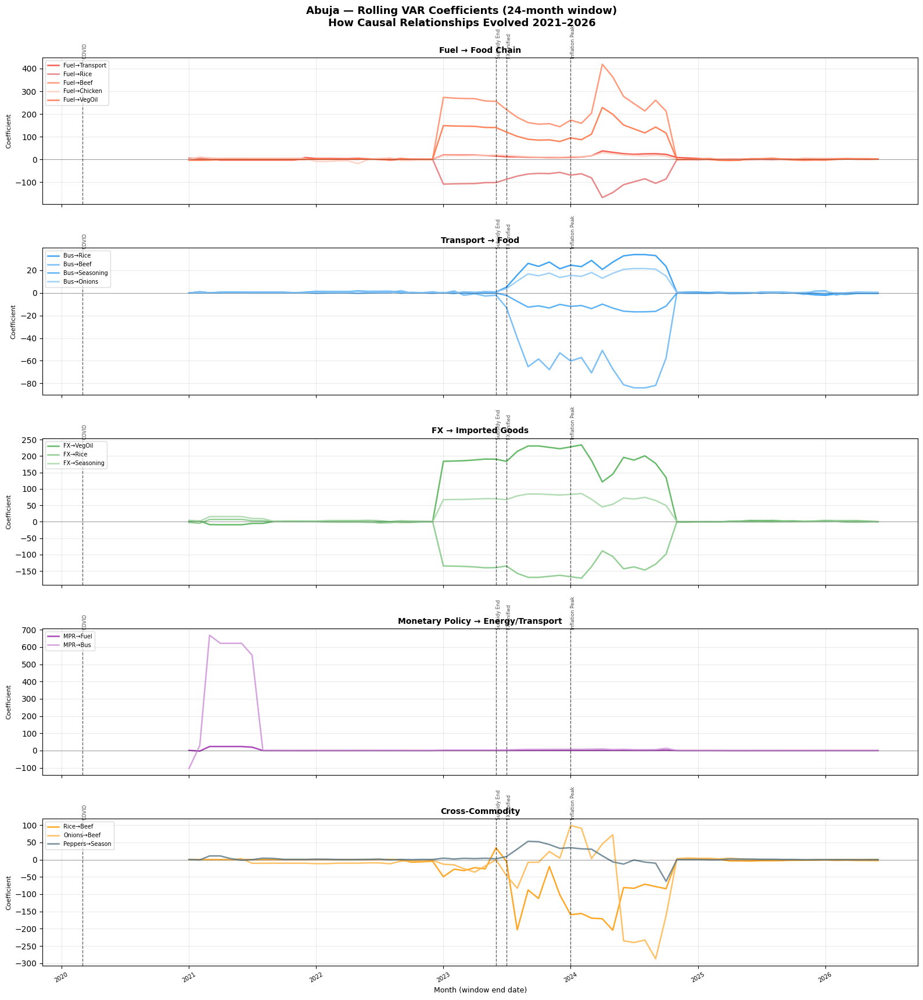

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2b_rolling_coefficients_Abuja.png


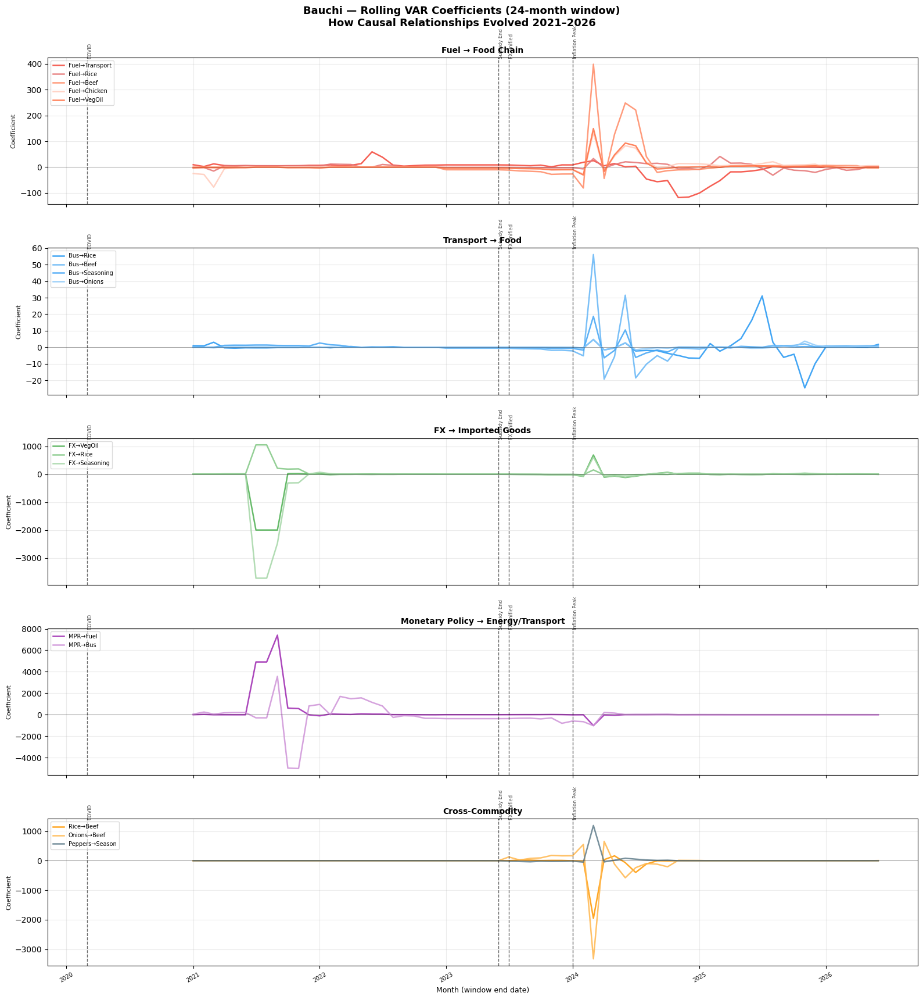

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2b_rolling_coefficients_Bauchi.png


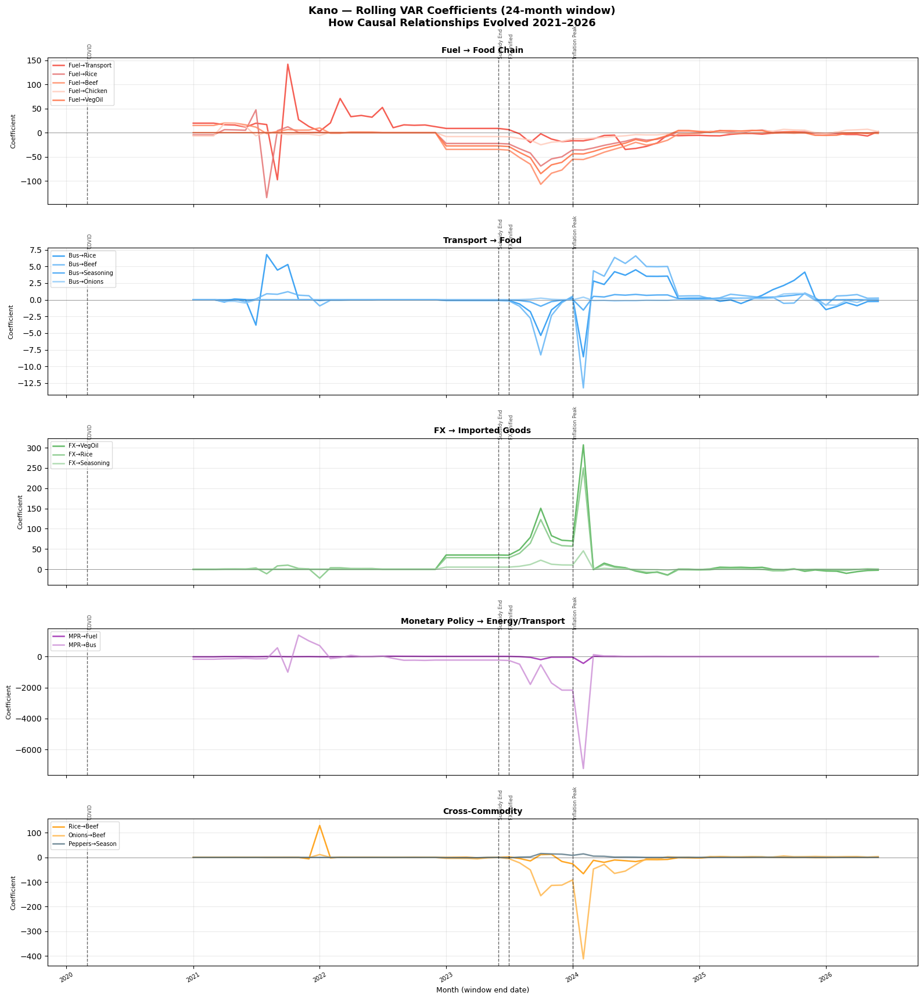

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2b_rolling_coefficients_Kano.png


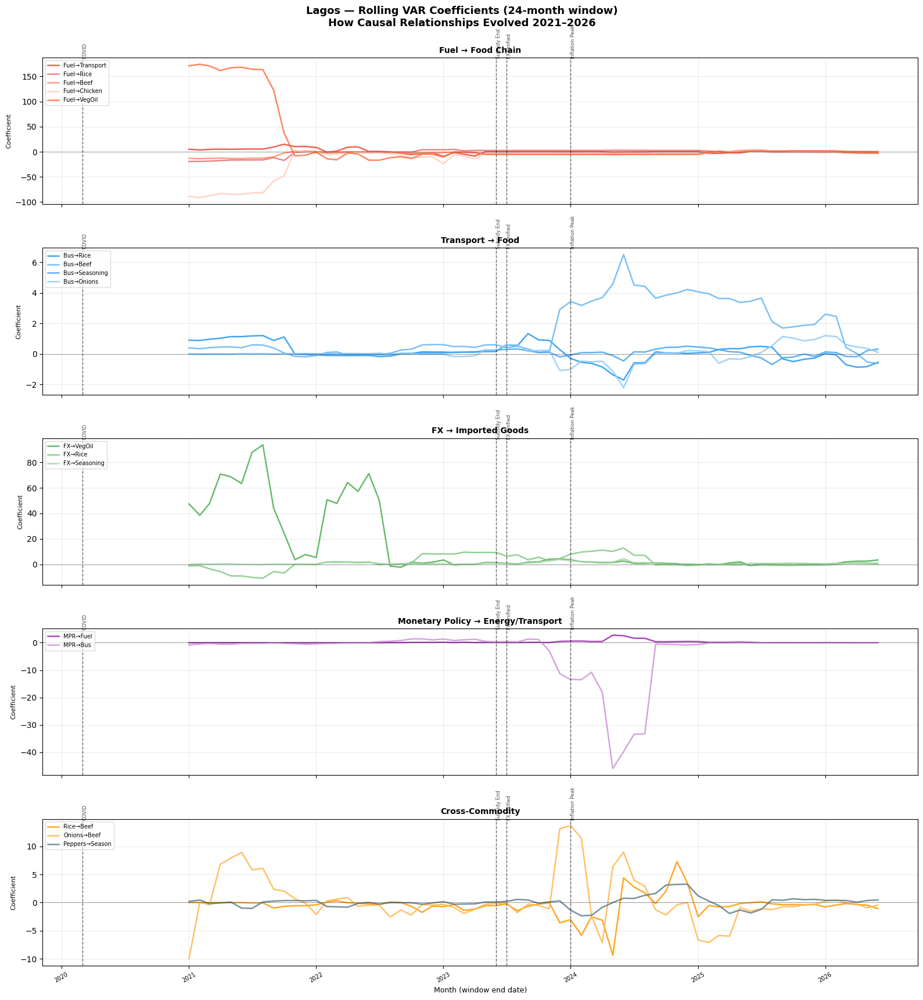

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2b_rolling_coefficients_Lagos.png


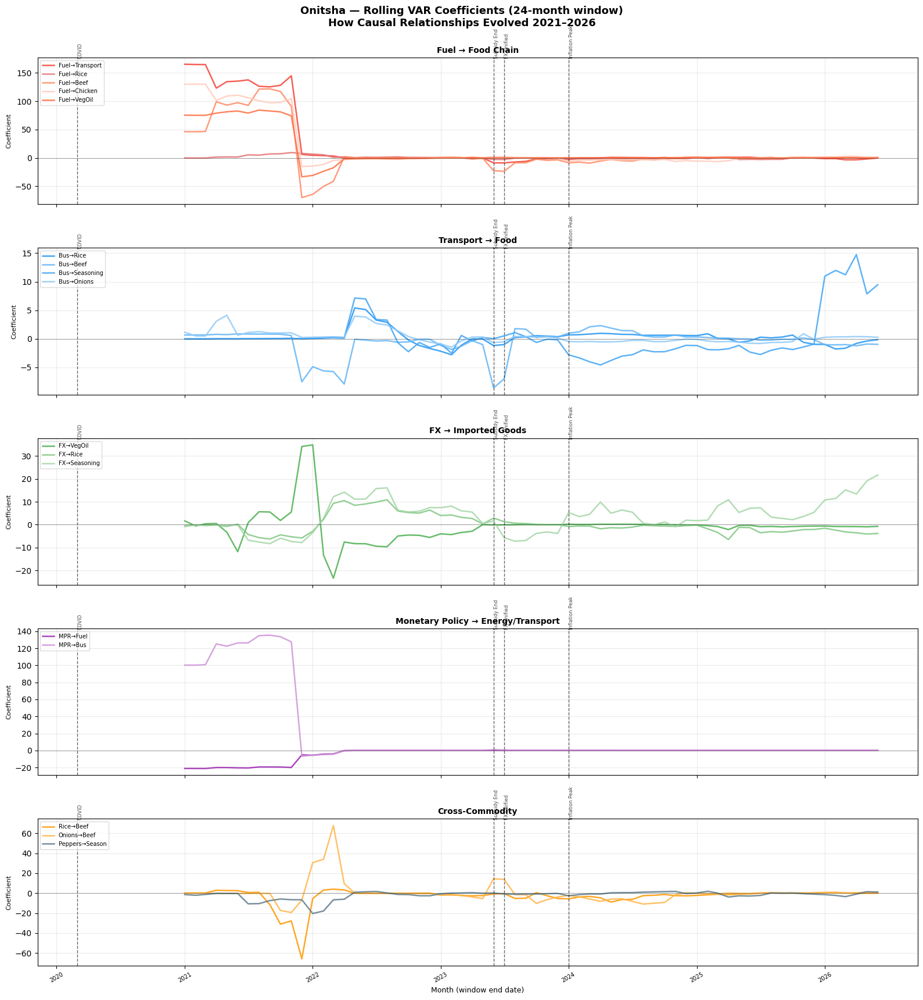

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2b_rolling_coefficients_Onitsha.png


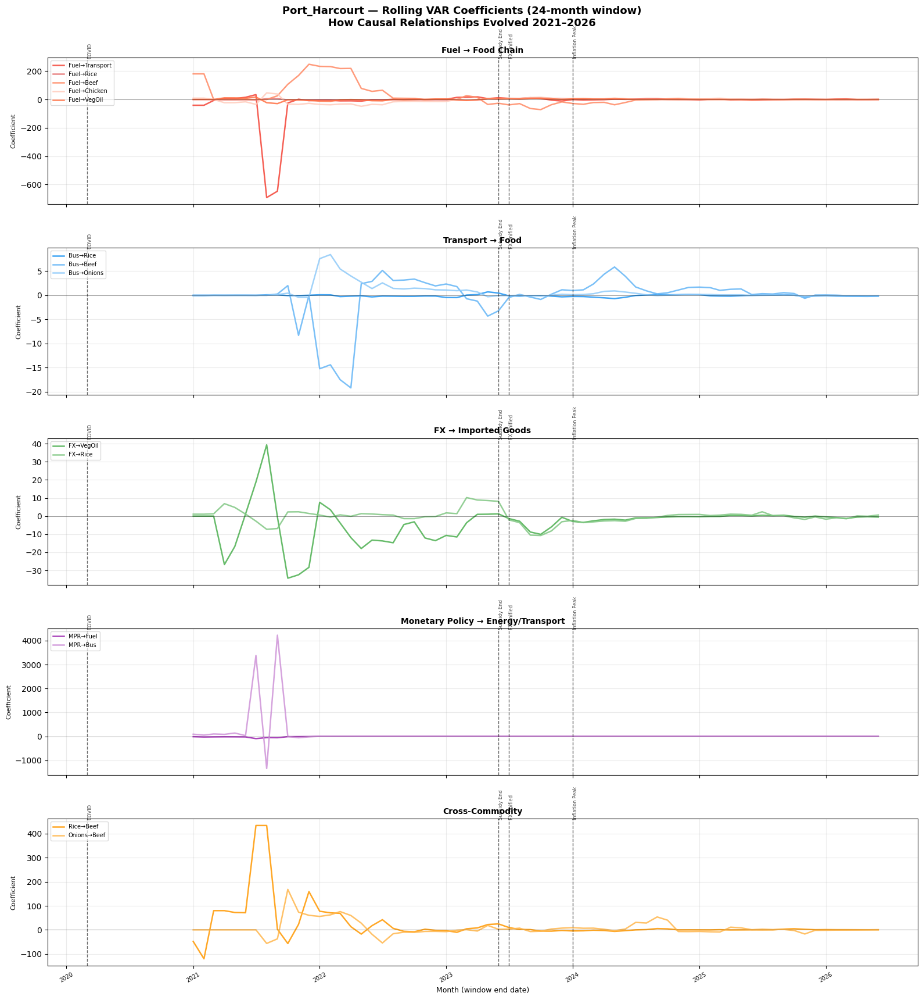

Saved: /content/drive/My Drive/Colab Notebooks/V3/S2b_rolling_coefficients_Port_Harcourt.png


In [ ]:
# ============================================================
# CELL 5 — Visualise Rolling Coefficients Per City
# 6 subplots per figure — one figure per city
# Shows how every key causal relationship evolved
# Sharp jumps reveal liquidity migration events
# Divergence between pairs shows commodity substitution
# ============================================================

# Colour scheme for relationship categories
PAIR_COLORS = {
    'PMS_Price→Bus_Intercity':  ('#F44336', 'Fuel→Transport'),
    'PMS_Price→Rice':           ('#E57373', 'Fuel→Rice'),
    'PMS_Price→Beef':           ('#FF8A65', 'Fuel→Beef'),
    'PMS_Price→Chicken':        ('#FFCCBC', 'Fuel→Chicken'),
    'PMS_Price→Veg_Oil':        ('#FF7043', 'Fuel→VegOil'),
    'Bus_Intercity→Rice':       ('#2196F3', 'Bus→Rice'),
    'Bus_Intercity→Beef':       ('#64B5F6', 'Bus→Beef'),
    'Bus_Intercity→Seasoning':  ('#42A5F5', 'Bus→Seasoning'),
    'Bus_Intercity→Onions':     ('#90CAF9', 'Bus→Onions'),
    'USD_NGN→Veg_Oil':          ('#4CAF50', 'FX→VegOil'),
    'USD_NGN→Rice':             ('#81C784', 'FX→Rice'),
    'USD_NGN→Seasoning':        ('#A5D6A7', 'FX→Seasoning'),
    'CBN_MPR→PMS_Price':        ('#9C27B0', 'MPR→Fuel'),
    'CBN_MPR→Bus_Intercity':    ('#CE93D8', 'MPR→Bus'),
    'Rice→Beef':                ('#FF9800', 'Rice→Beef'),
    'Onions→Beef':              ('#FFB74D', 'Onions→Beef'),
    'Red_Peppers→Seasoning':    ('#607D8B', 'Peppers→Season'),
}

for city in CITIES:
    rolling_df = rolling_var_results.get(city)
    if rolling_df is None or rolling_df.empty:
        continue

    # Group pairs into 6 panels by relationship category
    panels = {
        'Fuel → Food Chain':
            ['PMS_Price→Bus_Intercity', 'PMS_Price→Rice',
             'PMS_Price→Beef', 'PMS_Price→Chicken',
             'PMS_Price→Veg_Oil'],
        'Transport → Food':
            ['Bus_Intercity→Rice', 'Bus_Intercity→Beef',
             'Bus_Intercity→Seasoning', 'Bus_Intercity→Onions'],
        'FX → Imported Goods':
            ['USD_NGN→Veg_Oil', 'USD_NGN→Rice',
             'USD_NGN→Seasoning'],
        'Monetary Policy → Energy/Transport':
            ['CBN_MPR→PMS_Price', 'CBN_MPR→Bus_Intercity'],
        'Cross-Commodity':
            ['Rice→Beef', 'Onions→Beef',
             'Red_Peppers→Seasoning'],
    }

    n_panels = len(panels)
    fig, axes = plt.subplots(
        n_panels, 1,
        figsize=(16, 3.5 * n_panels),
        sharex=True
    )

    fig.suptitle(
        f'{city} — Rolling VAR Coefficients (24-month window)\n'
        f'How Causal Relationships Evolved 2021–2026',
        fontsize=13, fontweight='bold'
    )

    for panel_idx, (panel_title, pairs) in enumerate(panels.items()):
        ax = axes[panel_idx]

        for pair_key in pairs:
            if pair_key not in rolling_df.columns:
                continue
            series = rolling_df[pair_key].dropna()
            if len(series) < 3:
                continue

            color, label = PAIR_COLORS.get(
                pair_key, ('#BDBDBD', pair_key)
            )
            ax.plot(series.index, series.values,
                    color=color, linewidth=1.8,
                    alpha=0.85, label=label)

        # Mark structural breaks
        for break_date, break_label in STRUCTURAL_BREAKS.items():
            try:
                ax.axvline(
                    pd.Timestamp(break_date),
                    color='black', linestyle='--',
                    linewidth=1.0, alpha=0.6
                )
                ax.text(
                    pd.Timestamp(break_date),
                    ax.get_ylim()[1] if ax.get_ylim()[1] != 0 else 1,
                    break_label,
                    fontsize=6, rotation=90,
                    color='black', alpha=0.7
                )
            except Exception:
                pass

        ax.axhline(y=0, color='black',
                   linewidth=0.6, alpha=0.4)
        ax.set_title(panel_title,
                     fontweight='bold', fontsize=10)
        ax.set_ylabel('Coefficient', fontsize=8)
        ax.legend(fontsize=7, loc='upper left',
                  framealpha=0.7)
        ax.grid(True, alpha=0.25)
        ax.tick_params(axis='x', rotation=30, labelsize=7)

    axes[-1].set_xlabel('Month (window end date)', fontsize=9)
    plt.tight_layout()

    fname = DRIVE_PATH + f'S2b_rolling_coefficients_{city}.png'
    plt.savefig(fname, dpi=130, bbox_inches='tight')
    plt.show()
    print(f"Saved: {fname}")

In [ ]:
# ============================================================
# CELL 6 — Cross-City VAR — NetworkX Edge Weights
# For each commodity: model all cities simultaneously
# VAR coefficient city_i → city_j = edge weight in
# the supply network graph for Layer 2 NetworkX
# Boosted by Granger p-value significance
# ============================================================

print("Fitting cross-city VAR per commodity...")
print("Produces NetworkX edge weight matrix for Layer 2.")
print("=" * 65)

KEY_COMMODITIES = [
    'Tomatoes_Fresh', 'Rice', 'Beef', 'Chicken',
    'Veg_Oil', 'Onions', 'PMS_Price', 'Bus_Intercity'
]

networkx_weights = {}

for commodity in KEY_COMMODITIES:
    print(f"\n  {commodity}:")

    # Build city-panel — one column per city
    city_series = {}
    for city in CITIES:
        city_df = (df[df['city'] == city]
                   .sort_values('date')
                   .set_index('date'))
        if commodity in city_df.columns:
            city_series[city] = prepare_series(
                city_df[commodity]
            )

    panel = pd.DataFrame(city_series).dropna()
    if panel.shape[1] < 2:
        print(f"    Insufficient cities for cross-city VAR")
        continue

    print(f"    Panel: {panel.shape[0]} months × "
          f"{panel.shape[1]} cities")

    try:
        model  = VAR(panel)
        result = model.fit(2)

        n = len(CITIES)
        # Raw coefficient matrix from VAR
        raw_matrix     = np.zeros((n, n))
        # Granger-adjusted matrix
        adjusted_matrix = np.zeros((n, n))

        for j, effect_city in enumerate(CITIES):
            if effect_city not in result.params.columns:
                continue
            for i, cause_city in enumerate(CITIES):
                if i == j or cause_city not in panel.columns:
                    continue
                key = f'L1.{cause_city}'
                if key in result.params.index:
                    coef = float(
                        result.params.loc[key, effect_city]
                    )
                    raw_matrix[i, j] = abs(coef)
                    adjusted_matrix[i, j] = abs(coef)

        # Boost edges confirmed significant by Granger
        sig_pairs = granger_cross[
            (granger_cross['indicator'] == commodity) &
            (granger_cross['significant'] == True)
        ]
        for _, row in sig_pairs.iterrows():
            if (row['cause_city'] in CITIES and
                    row['effect_city'] in CITIES):
                i = CITIES.index(row['cause_city'])
                j = CITIES.index(row['effect_city'])
                # Granger boost: stronger significance = heavier edge
                boost = -np.log10(
                    float(row['p_value']) + 1e-10
                ) / 4.0
                adjusted_matrix[i, j] *= (1 + boost)

        networkx_weights[commodity] = {
            'cities':           CITIES,
            'raw_matrix':       raw_matrix.tolist(),
            'adjusted_matrix':  adjusted_matrix.tolist(),
            'lag':              2,
            'aic':              float(result.aic)
        }

        # Print significant edges
        printed = False
        for i in range(n):
            for j in range(n):
                if i != j and adjusted_matrix[i, j] > 0.005:
                    if not printed:
                        print(f"    Significant edges:")
                        printed = True
                    print(f"      {CITIES[i]:<15} → "
                          f"{CITIES[j]:<15} "
                          f"weight={adjusted_matrix[i,j]:.4f}")

        if not printed:
            print(f"    No edges above threshold")

        print(f"    AIC: {result.aic:.2f}")

    except Exception as e:
        print(f"    ERROR: {e}")
        networkx_weights[commodity] = None

with open(DRIVE_PATH + 'S2b_networkx_weights.json', 'w') as f:
    json.dump(networkx_weights, f,
              indent=2, default=json_serialise)

print(f"\nSaved: {DRIVE_PATH}S2b_networkx_weights.json")

Fitting cross-city VAR per commodity...
Produces NetworkX edge weight matrix for Layer 2.

  Tomatoes_Fresh:
    Panel: 89 months × 6 cities
    Significant edges:
      Abuja           → Bauchi          weight=0.0177
      Abuja           → Kano            weight=0.0533
      Abuja           → Lagos           weight=0.1160
      Abuja           → Onitsha         weight=0.0740
      Abuja           → Port_Harcourt   weight=0.2980
      Bauchi          → Abuja           weight=1.4955
      Bauchi          → Kano            weight=0.0720
      Bauchi          → Lagos           weight=0.7411
      Bauchi          → Onitsha         weight=0.3658
      Bauchi          → Port_Harcourt   weight=2.1379
      Kano            → Abuja           weight=0.5343
      Kano            → Bauchi          weight=2.3801
      Kano            → Lagos           weight=0.0061
      Kano            → Onitsha         weight=0.7523
      Kano            → Port_Harcourt   weight=0.1676
      Lagos           → Ab

In [ ]:
# ============================================================
# CELL 7 — Stage 2b Summary
# Full coefficient tensor per city
# Dynamic coefficient ranges from rolling VAR
# Files saved to Drive
# ============================================================

print("=" * 65)
print("STAGE 2b COMPLETE — VAR REGRESSION SUMMARY")
print("=" * 65)

for city in CITIES:
    var_res = full_var_results.get(city)
    weights = ctde_weights_all.get(city)

    if var_res is None or weights is None:
        print(f"\n{city}: VAR fitting failed")
        continue

    coef_tensor = weights.get('coef_tensor', {})

    print(f"\n{city}:")
    print(f"  VAR lag:      {var_res['lag']}")
    print(f"  Observations: {var_res['n_obs']}")
    print(f"  AIC:          {var_res['aic']:.2f}")
    print(f"  Variables:    {len(var_res['variables'])}")

    # Show top 3 strongest relationships per variable
    # No distinction by agent type here — fully symmetric
    print(f"  Strongest coefficients (lag 1) per variable:")
    for effect in var_res['variables']:
        if effect not in coef_tensor:
            continue
        causes = coef_tensor[effect]
        top = sorted(
            causes.items(),
            key=lambda x: abs(x[1][0]) if x[1] else 0,
            reverse=True
        )[:3]
        if top:
            top_str = '  '.join([
                f"{c}:{v[0]:+.3f}"
                for c, v in top
            ])
            print(f"    {effect:<20} ← {top_str}")

    # Rolling VAR coefficient ranges
    rolling_df = rolling_var_results.get(city)
    if rolling_df is not None and not rolling_df.empty:
        print(f"  Rolling VAR coefficient ranges "
              f"(min → max across 2021-2026):")
        for col in rolling_df.columns[:6]:
            series = rolling_df[col].dropna()
            if len(series) > 0:
                print(f"    {col:<35} "
                      f"{series.min():+.3f} → {series.max():+.3f}")

print()
print("=" * 65)
print("FILES SAVED TO DRIVE:")
print("=" * 65)
saved_files = [
    'S2b_ctde_weights.json',
    'S2b_var_summary.csv',
    'S2b_networkx_weights.json',
]
for city in CITIES:
    saved_files.append(f'S2b_rolling_var_{city}.csv')
    saved_files.append(f'S2b_rolling_coefficients_{city}.png')

for fname in saved_files:
    print(f"  {DRIVE_PATH}{fname}")

print()
print("NEXT STEP: Stage 3 — Persistent Homology + TDA")
print("  MinMaxScaler applied here for the first time")
print("  Reads: V3_Master_Wide.csv")
print("  Reads: S1_embedding_params_full.csv")
print("  Reads: S2b_ctde_weights.json")
print("  Produces: attractor topology per city")
print("            basin boundaries and stress thresholds")
print("            Voronoi proximity scores for Mesa agents")

STAGE 2b COMPLETE — VAR REGRESSION SUMMARY

Abuja:
  VAR lag:      6
  Observations: 89
  AIC:          -838.14
  Variables:    16
  Strongest coefficients (lag 1) per variable:
    Beef                 ← Thyme:-9.176  Curry:+3.329  Tinned_Tomatoes:-3.028
    Bus_Intercity        ← Red_Peppers:+1.242  Curry:-1.158  Thyme:-1.106
    CBN_MPR              ← Thyme:-0.022  Red_Peppers:+0.012  PMS_Price:-0.011
    Chicken              ← Thyme:+51.142  Curry:-15.230  Tinned_Tomatoes:+13.985
    Curry                ← Thyme:+14.404  Tinned_Tomatoes:+4.227  Chicken:-2.107
    Onions               ← Thyme:+8.949  Curry:-3.301  Tinned_Tomatoes:+2.411
    PMS_Price            ← Onions:-0.414  Curry:+0.359  Red_Peppers:+0.348
    Red_Peppers          ← Thyme:+8.498  Curry:-2.935  Tinned_Tomatoes:+2.470
    Rice                 ← Thyme:+9.506  Curry:-4.638  Seasoning:-2.440
    Salt                 ← Thyme:+11.168  Curry:-7.001  Tinned_Tomatoes:+4.699
    Seasoning            ← Thyme:+5.229  Tinned_

In [ ]:
# ============================================================
# STAGE 3 — PERSISTENT HOMOLOGY + TDA
# V3 Nigeria Food Price Intelligence
# First application of MinMaxScaler in the pipeline
# Produces: attractor topology per city
#           basin boundaries and stress thresholds
#           phase state inputs for Mesa agents
# ============================================================

# CELL 1 — Load, confirm and scale
# ============================================================
!pip install ripser persim scikit-learn scipy --quiet

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import json
import pickle
import warnings
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import pairwise_distances
from scipy.spatial import Voronoi, KDTree
warnings.filterwarnings('ignore')

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'

# Load master CSV
df = pd.read_csv(
    DRIVE_PATH + 'V3_Master_Wide.csv',
    parse_dates=['date']
)
df = df.sort_values(['city', 'date']).reset_index(drop=True)

# Load Stage 1 embedding parameters
params = pd.read_csv(
    DRIVE_PATH + 'S1_embedding_params_full.csv'
)

# Load Stage 2 confirmed causal variables
with open(DRIVE_PATH + 'S2_confirmed_causes.json', 'r') as f:
    confirmed_causes = json.load(f)

# Load Stage 2b CTDE weights
with open(DRIVE_PATH + 'S2b_ctde_weights.json', 'r') as f:
    ctde_weights = json.load(f)

CITIES = sorted(df['city'].unique())

print(f"Master CSV: {df.shape}")
print(f"Cities: {CITIES}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")

# ── Apply MinMaxScaler per city ─────────────────────────────
# Fitted on full 2019-2026 dataset
# Saved for Mesa runtime use
print("\nApplying MinMaxScaler per city...")
print("=" * 60)

scaled_data   = {}
city_scalers  = {}

for city in CITIES:
    city_df    = df[df['city'] == city].sort_values('date')
    causal_vars = confirmed_causes[city].get('all_causal_vars', [])
    available   = [v for v in causal_vars if v in city_df.columns]

    raw_matrix  = city_df[available].values.astype(float)

    # Forward-fill any remaining NaN before scaling
    raw_df      = pd.DataFrame(
        raw_matrix, columns=available,
        index=city_df['date'].values
    ).ffill().bfill()

    scaler      = MinMaxScaler()
    scaled_matrix = scaler.fit_transform(raw_df.values)

    scaled_df   = pd.DataFrame(
        scaled_matrix,
        columns=available,
        index=city_df['date'].values
    )

    scaled_data[city]  = scaled_df
    city_scalers[city] = {
        'scaler':    scaler,
        'variables': available,
        'data_min':  scaler.data_min_.tolist(),
        'data_max':  scaler.data_max_.tolist()
    }

    print(f"  {city:<15} {len(available)} variables scaled "
          f"→ [{scaled_matrix.min():.3f}, {scaled_matrix.max():.3f}]")

# Save scalers for Mesa runtime
scaler_params = {
    city: {
        'variables': v['variables'],
        'data_min':  v['data_min'],
        'data_max':  v['data_max']
    }
    for city, v in city_scalers.items()
}
with open(DRIVE_PATH + 'S3_scalers.json', 'w') as f:
    json.dump(scaler_params, f, indent=2)

print(f"\nScalers saved: {DRIVE_PATH}S3_scalers.json")
print("Ready for delay embedding.")

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 842.1/842.1 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.6/48.6 kB 2.8 MB/s eta 0:00:00
Mounted at /content/drive
Master CSV: (540, 18)
Cities: ['Abuja', 'Bauchi', 'Kano', 'Lagos', 'Onitsha', 'Port_Harcourt']
Date range: 2019-01-01 00:00:00 to 2026-06-01 00:00:00

Applying MinMaxScaler per city...
  Abuja           16 variables scaled → [0.000, 1.000]
  Bauchi          16 variables scaled → [0.000, 1.000]
  Kano            16 variables scaled → [0.000, 1.000]
  Lagos           16 variables scaled → [0.000, 1.000]
  Onitsha         16 variables scaled → [0.000, 1.000]
  Port_Harcourt   14 variables scaled → [0.000, 1.000]

Scalers saved: /content/drive/My Drive/Colab Notebooks/V3/S3_scalers.json
Ready for delay embedding.


In [ ]:
# ============================================================
# CELL 2 — Multivariate Delay Embedding on Scaled Data
# Uses Stage 1 τ and d per indicator per city
# Each month becomes a point in d-dimensional phase space
# The 90 monthly points trace the market attractor trajectory
# ============================================================

def build_scaled_embedding(scaled_df, city, params,
                            confirmed_causes):
    """
    Build multivariate delay embedding on scaled data.
    For each confirmed causal variable, use its city-specific
    τ and d from Stage 1 to create delay vectors.
    Concatenate all delay vectors into joint embedding matrix.
    Returns: embedding matrix, dates, variable list used
    """
    causal_vars = confirmed_causes[city].get(
        'all_causal_vars', []
    )
    available = [v for v in causal_vars
                 if v in scaled_df.columns]

    # Get τ and d for each variable
    city_params = params[params['city'] == city]

    embeddings = []
    vars_used  = []
    min_len    = np.inf

    for var in available:
        var_row = city_params[city_params['indicator'] == var]
        if len(var_row) == 0:
            tau, d = 2, 1
        else:
            tau = int(var_row['tau'].iloc[0])
            d   = int(var_row['d'].iloc[0])

        series  = scaled_df[var].values
        n       = len(series)
        n_vecs  = n - tau * (d - 1)

        if n_vecs < 10 or d < 1:
            continue

        # Build delay vectors for this variable
        emb = np.array([
            series[i: i + tau * d: tau]
            for i in range(n_vecs)
        ])

        embeddings.append(emb)
        vars_used.append(var)
        min_len = min(min_len, n_vecs)

    if not embeddings or np.isinf(min_len):
        return None, None, []

    min_len = int(min_len)

    # Concatenate all variable embeddings — same length
    joint   = np.concatenate(
        [e[:min_len] for e in embeddings], axis=1
    )
    dates   = scaled_df.index[-min_len:]

    return joint, dates, vars_used


print("Building scaled multivariate delay embeddings...")
print("=" * 60)

city_embeddings = {}

for city in CITIES:
    scaled_df = scaled_data[city]
    joint, dates, vars_used = build_scaled_embedding(
        scaled_df, city, params, confirmed_causes
    )

    if joint is None:
        print(f"  {city}: embedding failed")
        continue

    city_embeddings[city] = {
        'embedding': joint,
        'dates':     dates,
        'vars_used': vars_used,
        'n_points':  joint.shape[0],
        'n_dims':    joint.shape[1]
    }

    print(f"  {city:<15} "
          f"shape={joint.shape}  "
          f"dims={joint.shape[1]}  "
          f"vars={len(vars_used)}")

print(f"\nEmbeddings built for {len(city_embeddings)} cities.")
print("Ready for persistent homology.")

Building scaled multivariate delay embeddings...
  Abuja           shape=(83, 23)  dims=23  vars=16
  Bauchi          shape=(80, 23)  dims=23  vars=16
  Kano            shape=(80, 25)  dims=25  vars=16
  Lagos           shape=(40, 24)  dims=24  vars=16
  Onitsha         shape=(68, 20)  dims=20  vars=16
  Port_Harcourt   shape=(68, 23)  dims=23  vars=14

Embeddings built for 6 cities.
Ready for persistent homology.


In [ ]:
# ============================================================
# CELL 3 — Persistent Homology via Ripser
# Replaces giotto-tda version if that fails to install
# Ripser is faster and more stable in Colab
# Same outputs: H0, H1, persistence diagrams, stress threshold
# ============================================================

import ripser
import persim
import matplotlib.pyplot as plt
import numpy as np

print("Running persistent homology per city using Ripser...")
print("H0 = connected components  H1 = loops (seasonal cycles)")
print("=" * 65)

persistence_results = {}

for city in CITIES:
    emb_data = city_embeddings.get(city)
    if emb_data is None:
        print(f"  {city}: no embedding found")
        continue

    embedding = emb_data['embedding'].astype(np.float64)
    dates     = emb_data['dates']

    # Normalise embedding dimensions to [0,1]
    emb_min   = embedding.min(axis=0)
    emb_max   = embedding.max(axis=0)
    emb_range = emb_max - emb_min
    emb_range[emb_range == 0] = 1.0
    emb_norm  = (embedding - emb_min) / emb_range

    try:
        # Run Ripser — computes H0 and H1 persistence
        # maxdim=1 means we compute H0 and H1 only
        # thresh limits max edge length for speed
        result = ripser.ripser(
            emb_norm,
            maxdim=1,
            thresh=2.0
        )

        dgms = result['dgms']

        # H0: connected components
        # H1: loops
        h0_dgm = dgms[0]  # shape (n, 2): birth, death
        h1_dgm = dgms[1]  # shape (n, 2): birth, death

        # Remove infinite death values for H0
        # (one H0 feature always has infinite death = main component)
        h0_finite = h0_dgm[h0_dgm[:, 1] < np.inf]
        h1_finite = h1_dgm[h1_dgm[:, 1] < np.inf]

        # Persistence = death - birth
        h0_persistence = (h0_finite[:, 1] - h0_finite[:, 0]
                          if len(h0_finite) > 0
                          else np.array([0.0]))
        h1_persistence = (h1_finite[:, 1] - h1_finite[:, 0]
                          if len(h1_finite) > 0
                          else np.array([0.0]))

        # Most persistent H1 loop = dominant seasonal cycle
        if len(h1_persistence) > 0 and h1_persistence.max() > 0:
            max_h1_idx       = np.argmax(h1_persistence)
            h1_birth         = float(h1_finite[max_h1_idx, 0])
            h1_death         = float(h1_finite[max_h1_idx, 1])
            h1_max_persist   = float(h1_persistence[max_h1_idx])
            stress_threshold = h1_death
        else:
            h1_birth         = 0.0
            h1_death         = 0.5
            h1_max_persist   = 0.0
            stress_threshold = 0.5

        # Number of significant H0 components
        if len(h0_persistence) > 0:
            h0_med    = np.median(h0_persistence)
            n_regimes = int((h0_persistence > h0_med).sum()) + 1
        else:
            n_regimes = 1

        n_regimes = max(2, min(n_regimes, 4))

        persistence_results[city] = {
            'h0_dgm':            h0_dgm,
            'h1_dgm':            h1_dgm,
            'h0_finite':         h0_finite,
            'h1_finite':         h1_finite,
            'h1_birth':          h1_birth,
            'h1_death':          h1_death,
            'h1_persistence':    h1_max_persist,
            'h1_all_persist':    h1_persistence,
            'stress_threshold':  stress_threshold,
            'n_regimes':         n_regimes,
            'embedding':         emb_norm,
            'dates':             dates
        }

        print(f"\n  {city}:")
        print(f"    H0 components:     {len(h0_dgm)} "
              f"({len(h0_finite)} finite)")
        print(f"    H1 loops:          {len(h1_finite)}")
        print(f"    H1 max persist:    {h1_max_persist:.4f} "
              f"(birth={h1_birth:.4f} "
              f"death={h1_death:.4f})")
        print(f"    Stress threshold:  {stress_threshold:.4f}")
        print(f"    Regimes detected:  {n_regimes}")
        print(f"    Seasonal cycle:    "
              f"{'Strong' if h1_max_persist > 0.1 else 'Weak/disrupted'}")

    except Exception as e:
        print(f"  {city}: ERROR — {e}")
        import traceback
        traceback.print_exc()

print(f"\nPersistent homology complete: "
      f"{len(persistence_results)}/{len(CITIES)} cities")

Running persistent homology per city using Ripser...
H0 = connected components  H1 = loops (seasonal cycles)

  Abuja:
    H0 components:     83 (82 finite)
    H1 loops:          4
    H1 max persist:    0.1222 (birth=0.7941 death=0.9163)
    Stress threshold:  0.9163
    Regimes detected:  4
    Seasonal cycle:    Strong

  Bauchi:
    H0 components:     80 (79 finite)
    H1 loops:          1
    H1 max persist:    0.0000 (birth=0.0319 death=0.0320)
    Stress threshold:  0.0320
    Regimes detected:  4
    Seasonal cycle:    Weak/disrupted

  Kano:
    H0 components:     80 (79 finite)
    H1 loops:          3
    H1 max persist:    0.0735 (birth=0.9916 death=1.0650)
    Stress threshold:  1.0650
    Regimes detected:  4
    Seasonal cycle:    Weak/disrupted

  Lagos:
    H0 components:     40 (39 finite)
    H1 loops:          1
    H1 max persist:    0.0958 (birth=0.7579 death=0.8537)
    Stress threshold:  0.8537
    Regimes detected:  4
    Seasonal cycle:    Weak/disrupted

  

In [ ]:
# ============================================================
# CELL 4 — CORRECTED
# Regime Clustering and Voronoi Basin Boundaries
# Fix: attractor = cluster most represented in pre-2020 months
# not label-based selection which was misidentifying regimes
# ============================================================

from scipy.spatial import KDTree
from sklearn.cluster import KMeans
from collections import Counter

print("Computing regime clusters and Voronoi basin boundaries...")
print("=" * 65)

PERIOD_MAP = {
    ('2019-01', '2019-12'): 'Pre-COVID stable',
    ('2020-01', '2021-12'): 'COVID disruption',
    ('2022-01', '2022-12'): 'Post-COVID recovery',
    ('2023-01', '2023-12'): 'Subsidy/FX shock',
    ('2024-01', '2024-12'): 'High inflation',
    ('2025-01', '2026-06'): 'Partial easing',
}

def get_period_label(date):
    ds = pd.Timestamp(date).strftime('%Y-%m')
    for (start, end), label in PERIOD_MAP.items():
        if start <= ds <= end:
            return label
    return 'Unknown'

basin_results = {}

for city in CITIES:
    ph_data  = persistence_results.get(city)
    emb_data = city_embeddings.get(city)

    if ph_data is None or emb_data is None:
        print(f"  {city}: skipped")
        continue

    embedding = ph_data['embedding']   # normalised embedding
    dates     = ph_data['dates']
    n_points  = embedding.shape[0]
    n_regimes = ph_data['n_regimes']
    n_clusters = max(2, min(n_regimes, 4))

    # ── Step 1: Cluster into market regimes ────────────────
    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=20
    )
    cluster_labels = kmeans.fit_predict(embedding)
    centroids      = kmeans.cluster_centers_

    # Label each cluster with its dominant economic period
    cluster_period_labels = {}
    for k in range(n_clusters):
        mask          = cluster_labels == k
        cluster_dates = dates[mask]
        periods       = [get_period_label(d) for d in cluster_dates]
        dominant      = max(set(periods), key=periods.count)
        cluster_period_labels[k] = dominant

    # ── Step 2: Identify attractor correctly ───────────────
    # Attractor = cluster most represented in pre-2020 months
    # This is the stable baseline before COVID and shocks
    # NOT label-based — uses actual temporal position
    pre2020_mask = np.array([
        pd.Timestamp(d) < pd.Timestamp('2020-01-01')
        for d in dates
    ])

    if pre2020_mask.sum() > 0:
        pre2020_clusters = cluster_labels[pre2020_mask]
        attractor_idx    = Counter(
            pre2020_clusters
        ).most_common(1)[0][0]
    else:
        # Fallback: use cluster closest to embedding origin
        # (most compressed = most stable)
        origin       = np.zeros(embedding.shape[1])
        dists_origin = np.linalg.norm(
            centroids - origin, axis=1
        )
        attractor_idx = int(np.argmin(dists_origin))

    attractor_centroid = centroids[attractor_idx]

    # ── Step 3: Voronoi tessellation ───────────────────────
    centroid_tree = KDTree(centroids)

    # ── Step 4: basin_proximity_score per month ────────────
    basin_scores          = []
    distances_to_nearest  = []
    regime_labels         = []
    distances_to_attractor = []

    for i in range(n_points):
        point = embedding[i]

        # Nearest and second-nearest centroid
        dists, idxs = centroid_tree.query(
            point, k=min(2, n_clusters)
        )
        dist_nearest = float(dists[0])
        dist_second  = float(dists[1]) if len(dists) > 1 else 1.0

        # Proximity: 0 = deep inside basin, 0.5 = on boundary
        proximity = dist_nearest / (
            dist_nearest + dist_second + 1e-10
        )

        # Distance to stable attractor centroid
        dist_att = float(np.linalg.norm(
            point - attractor_centroid
        ))

        basin_scores.append(float(proximity))
        distances_to_nearest.append(dist_nearest)
        distances_to_attractor.append(dist_att)
        regime_labels.append(
            cluster_period_labels.get(
                cluster_labels[i], 'Unknown'
            )
        )

    basin_scores_arr         = np.array(basin_scores)
    distances_arr            = np.array(distances_to_nearest)
    distances_to_attractor_arr = np.array(distances_to_attractor)

    basin_results[city] = {
        'cluster_labels':          cluster_labels,
        'centroids':               centroids,
        'n_clusters':              n_clusters,
        'cluster_period_labels':   cluster_period_labels,
        'basin_proximity_scores':  basin_scores_arr,
        'distances_to_nearest':    distances_arr,
        'distances_to_attractor':  distances_to_attractor_arr,
        'attractor_centroid':      attractor_centroid,
        'attractor_idx':           attractor_idx,
        'dates':                   dates,
        'regime_labels':           regime_labels,
        'embedding':               embedding,
    }

    # Count pre-2020 months in attractor cluster
    pre2020_in_attractor = (
        pre2020_mask & (cluster_labels == attractor_idx)
    ).sum()

    print(f"\n  {city}:")
    print(f"    Market regimes found: {n_clusters}")
    for k, label in cluster_period_labels.items():
        count  = (cluster_labels == k).sum()
        marker = ' ← attractor (pre-2020 baseline)' \
                 if k == attractor_idx else ''
        print(f"      Regime {k}: {label:<28} "
              f"({count} months){marker}")
    print(f"    Pre-2020 months in attractor: "
          f"{pre2020_in_attractor} / {pre2020_mask.sum()}")
    print(f"    Basin proximity — "
          f"mean={basin_scores_arr.mean():.3f}  "
          f"max={basin_scores_arr.max():.3f}")
    print(f"    Distance to attractor — "
          f"mean={distances_to_attractor_arr.mean():.3f}  "
          f"max={distances_to_attractor_arr.max():.3f}")

print(f"\nBasin boundaries computed for {len(basin_results)} cities.")

Computing regime clusters and Voronoi basin boundaries...

  Abuja:
    Market regimes found: 4
      Regime 0: COVID disruption             (33 months) ← attractor (pre-2020 baseline)
      Regime 1: Partial easing               (18 months)
      Regime 2: Post-COVID recovery          (18 months)
      Regime 3: High inflation               (14 months)
    Pre-2020 months in attractor: 5 / 5
    Basin proximity — mean=0.261  max=0.468
    Distance to attractor — mean=1.575  max=3.025

  Bauchi:
    Market regimes found: 4
      Regime 0: Partial easing               (12 months)
      Regime 1: COVID disruption             (48 months) ← attractor (pre-2020 baseline)
      Regime 2: High inflation               (12 months)
      Regime 3: Partial easing               (8 months)
    Pre-2020 months in attractor: 2 / 2
    Basin proximity — mean=0.241  max=0.474
    Distance to attractor — mean=1.271  max=3.846

  Kano:
    Market regimes found: 4
      Regime 0: Post-COVID recovery      

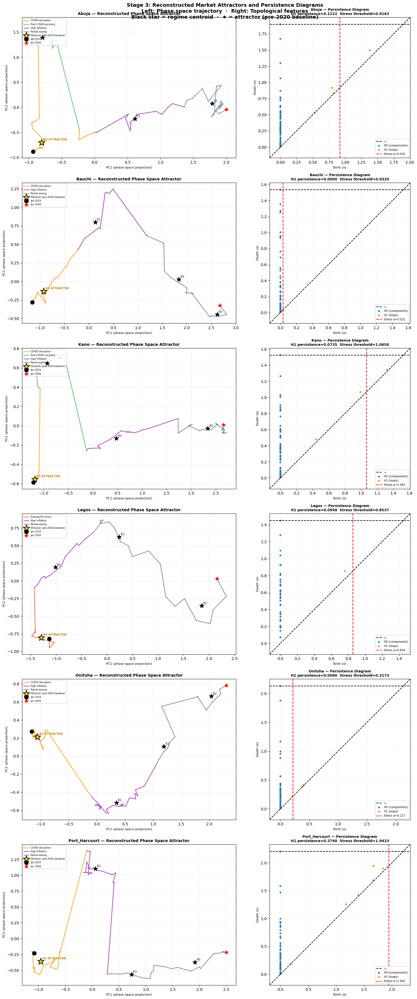

Saved: /content/drive/My Drive/Colab Notebooks/V3/S3_phase_space_persistence.png


In [ ]:
# ============================================================
# CELL 5 — CORRECTED
# Visualise Phase Space and Persistence Diagrams
# Uses corrected attractor from Cell 4
# Left: 2D PCA projection coloured by economic period
# Right: Persistence diagram with stress threshold
# ============================================================

from sklearn.decomposition import PCA
import persim
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

PERIOD_COLORS = {
    'Pre-COVID stable':    '#1565C0',
    'COVID disruption':    '#FF9800',
    'Post-COVID recovery': '#4CAF50',
    'Subsidy/FX shock':    '#F44336',
    'High inflation':      '#9C27B0',
    'Partial easing':      '#607D8B',
    'Unknown':             '#BDBDBD',
}

fig, axes = plt.subplots(6, 2, figsize=(16, 36))
fig.suptitle(
    'Stage 3: Reconstructed Market Attractors and Persistence Diagrams\n'
    'Left: Phase space trajectory  ·  Right: Topological features\n'
    'Black star = regime centroid  ·  ★ = attractor (pre-2020 baseline)',
    fontsize=13, fontweight='bold'
)

for row_idx, city in enumerate(CITIES):
    ph_data    = persistence_results.get(city)
    basin_data = basin_results.get(city)

    if ph_data is None or basin_data is None:
        continue

    embedding   = ph_data['embedding']
    dates       = basin_data['dates']
    h0_dgm     = ph_data['h0_dgm']
    h1_dgm     = ph_data['h1_dgm']
    h0_finite   = ph_data['h0_finite']
    h1_finite   = ph_data['h1_finite']

    ax_phase    = axes[row_idx, 0]
    ax_persist  = axes[row_idx, 1]

    # ── Left panel: phase space trajectory ─────────────────
    if embedding.shape[1] >= 2:
        if embedding.shape[1] > 2:
            pca    = PCA(n_components=2, random_state=42)
            emb2   = pca.fit_transform(embedding)
            xlabel = 'PC1 (phase space projection)'
            ylabel = 'PC2 (phase space projection)'
        else:
            emb2   = embedding
            xlabel = 'Dim 1'
            ylabel = 'Dim 2'

        # Plot trajectory coloured by economic period
        legend_added = set()
        for i in range(len(dates) - 1):
            period = basin_data['regime_labels'][i]
            color  = PERIOD_COLORS.get(period, '#BDBDBD')
            ax_phase.plot(
                [emb2[i, 0],     emb2[i + 1, 0]],
                [emb2[i, 1],     emb2[i + 1, 1]],
                color=color, linewidth=1.8, alpha=0.8,
                label=period if period not in legend_added else ''
            )
            legend_added.add(period)

        # Plot regime centroids
        if embedding.shape[1] > 2:
            centroids_2d = pca.transform(basin_data['centroids'])
        else:
            centroids_2d = basin_data['centroids']

        attractor_idx = basin_data['attractor_idx']

        for k, c2d in enumerate(centroids_2d):
            if k == attractor_idx:
                # Attractor gets a gold star marker
                ax_phase.scatter(
                    c2d[0], c2d[1],
                    s=300, marker='*',
                    color='gold', edgecolors='black',
                    linewidths=1.5, zorder=12,
                    label='Attractor (pre-2020 baseline)'
                )
                ax_phase.annotate(
                    f'R{k} ATTRACTOR',
                    (c2d[0], c2d[1]),
                    fontsize=7, fontweight='bold',
                    color='darkgoldenrod',
                    xytext=(5, 5),
                    textcoords='offset points'
                )
            else:
                ax_phase.scatter(
                    c2d[0], c2d[1],
                    s=150, marker='*',
                    color='black', zorder=11
                )
                label_str = basin_data['cluster_period_labels'].get(
                    k, f'R{k}'
                )
                ax_phase.annotate(
                    f'R{k}',
                    (c2d[0], c2d[1]),
                    fontsize=7,
                    xytext=(4, 4),
                    textcoords='offset points'
                )

        # Start and end markers
        ax_phase.scatter(
            emb2[0, 0], emb2[0, 1],
            s=100, color='black',
            zorder=13, marker='o', label='Jan 2019'
        )
        ax_phase.scatter(
            emb2[-1, 0], emb2[-1, 1],
            s=100, color='red',
            zorder=13, marker='*', label='Jun 2026'
        )

        ax_phase.set_title(
            f'{city} — Reconstructed Phase Space Attractor',
            fontweight='bold', fontsize=10
        )
        ax_phase.set_xlabel(xlabel, fontsize=8)
        ax_phase.set_ylabel(ylabel, fontsize=8)
        ax_phase.grid(True, alpha=0.25)
        ax_phase.legend(fontsize=6, loc='upper left',
                        framealpha=0.8, ncol=1)

    # ── Right panel: persistence diagram ───────────────────
    st      = ph_data['stress_threshold']
    h1_pers = ph_data['h1_persistence']

    try:
        persim.plot_diagrams(
            [h0_dgm, h1_dgm],
            labels=['H0 (components)', 'H1 (loops)'],
            ax=ax_persist,
            show=False
        )
    except Exception:
        # Manual fallback
        ax_persist.plot([0, 2], [0, 2], 'k--',
                        linewidth=0.8, alpha=0.4)
        if len(h0_finite) > 0:
            ax_persist.scatter(
                h0_finite[:, 0], h0_finite[:, 1],
                c='#2196F3', s=25, alpha=0.8,
                label=f'H0 ({len(h0_finite)})', zorder=5
            )
        if len(h1_finite) > 0:
            ax_persist.scatter(
                h1_finite[:, 0], h1_finite[:, 1],
                c='#FF9800', s=25, alpha=0.8,
                label=f'H1 ({len(h1_finite)})', zorder=5
            )
        ax_persist.legend(fontsize=7)

    # Stress threshold vertical line
    ax_persist.axvline(
        x=st, color='red', linestyle='--',
        linewidth=1.8, alpha=0.9,
        label=f'Stress α={st:.3f}'
    )

    ax_persist.set_title(
        f'{city} — Persistence Diagram\n'
        f'H1 persistence={h1_pers:.4f}  '
        f'Stress threshold={st:.4f}',
        fontweight='bold', fontsize=9
    )
    ax_persist.set_xlabel('Birth (α)', fontsize=8)
    ax_persist.set_ylabel('Death (α)', fontsize=8)
    ax_persist.grid(True, alpha=0.2)
    ax_persist.legend(fontsize=7, loc='lower right')

plt.tight_layout()
fname = DRIVE_PATH + 'S3_phase_space_persistence.png'
plt.savefig(fname, dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved: {fname}")

In [ ]:
# ============================================================
# CELL 6 — NO CHANGE FROM ORIGINAL
# Build Mesa Phase State Input Table
# Reads from corrected basin_results from Cell 4
# All four phase state values per month per city
# ============================================================

print("Building Mesa phase state input table...")
print("=" * 65)

all_phase_state_rows = []

for city in CITIES:
    ph_data    = persistence_results.get(city)
    basin_data = basin_results.get(city)

    if ph_data is None or basin_data is None:
        print(f"  {city}: skipped")
        continue

    dates                  = basin_data['dates']
    distances_to_attractor = basin_data['distances_to_attractor']
    basin_proximity_scores = basin_data['basin_proximity_scores']
    regime_labels          = basin_data['regime_labels']
    stress_threshold       = ph_data['stress_threshold']
    h1_persistence         = ph_data['h1_persistence']
    n_regimes              = ph_data['n_regimes']
    attractor_idx          = basin_data['attractor_idx']
    cluster_period_labels  = basin_data['cluster_period_labels']

    for i, date in enumerate(dates):
        dist_att   = float(distances_to_attractor[i])
        basin_prox = float(basin_proximity_scores[i])

        # Normalise distance to attractor using stress threshold
        # 0 = at attractor centroid
        # 1 = at stress threshold boundary
        # >1 = beyond stress threshold (crisis zone)
        dist_normalised = dist_att / (stress_threshold + 1e-10)
        stress_flag     = int(dist_att > stress_threshold)

        all_phase_state_rows.append({
            'city':                    city,
            'date':                    pd.Timestamp(date),
            'distance_to_attractor':   round(dist_att, 6),
            'distance_normalised':     round(dist_normalised, 6),
            'basin_proximity_score':   round(basin_prox, 6),
            'stress_threshold':        round(stress_threshold, 6),
            'stress_flag':             stress_flag,
            'regime_label':            regime_labels[i],
            'attractor_regime':        cluster_period_labels.get(
                                           attractor_idx, 'Unknown'
                                       ),
            'h1_persistence':          round(h1_persistence, 6),
            'n_regimes':               n_regimes
        })

    n_stressed  = sum(
        1 for r in all_phase_state_rows[-len(dates):]
        if r['stress_flag'] == 1
    )
    pct_stress  = 100 * n_stressed / len(dates)

    print(f"  {city}: {len(dates)} months  "
          f"attractor='{cluster_period_labels.get(attractor_idx)}'  "
          f"stressed={n_stressed}({pct_stress:.0f}%)")

phase_state_df = pd.DataFrame(all_phase_state_rows)
phase_state_df = phase_state_df.sort_values(
    ['city', 'date']
).reset_index(drop=True)

phase_state_df.to_csv(
    DRIVE_PATH + 'S3_phase_state.csv', index=False
)

print(f"\nPhase state table: {phase_state_df.shape}")
print(f"Saved: {DRIVE_PATH}S3_phase_state.csv")
print(f"\nSample — Lagos 2019-2020 (should be near attractor):")
print(
    phase_state_df[
        (phase_state_df['city'] == 'Lagos') &
        (phase_state_df['date'] < '2020-06-01')
    ][[
        'date', 'distance_to_attractor',
        'basin_proximity_score', 'stress_flag',
        'regime_label', 'attractor_regime'
    ]].to_string()
)

Building Mesa phase state input table...
  Abuja: 83 months  attractor='COVID disruption'  stressed=55(66%)
  Bauchi: 80 months  attractor='COVID disruption'  stressed=80(100%)
  Kano: 80 months  attractor='COVID disruption'  stressed=54(68%)
  Lagos: 40 months  attractor='Subsidy/FX shock'  stressed=34(85%)
  Onitsha: 68 months  attractor='COVID disruption'  stressed=49(72%)
  Port_Harcourt: 68 months  attractor='COVID disruption'  stressed=23(34%)

Phase state table: (419, 11)
Saved: /content/drive/My Drive/Colab Notebooks/V3/S3_phase_state.csv

Sample — Lagos 2019-2020 (should be near attractor):
Empty DataFrame
Columns: [date, distance_to_attractor, basin_proximity_score, stress_flag, regime_label, attractor_regime]
Index: []


In [ ]:
# ============================================================
# CELL 7 — Stage 3 Summary
# Stress thresholds, regime structures, H1 persistence
# per city — handover document to Layer 2 and Mesa
# ============================================================

print("=" * 65)
print("STAGE 3 COMPLETE — PERSISTENT HOMOLOGY + TDA SUMMARY")
print("=" * 65)

# Load saved phase state for verification
phase_df = pd.read_csv(
    DRIVE_PATH + 'S3_phase_state.csv',
    parse_dates=['date']
)

for city in CITIES:
    ph_data    = persistence_results.get(city)
    basin_data = basin_results.get(city)

    if ph_data is None:
        print(f"\n{city}: no results")
        continue

    city_phase = phase_df[phase_df['city'] == city]
    n_stressed = city_phase['stress_flag'].sum()
    pct_stress = 100 * n_stressed / len(city_phase)

    print(f"\n{city}:")
    print(f"  H1 persistence (seasonal cycle):  "
          f"{ph_data['h1_persistence']:.4f}")
    print(f"  Stress threshold α:               "
          f"{ph_data['stress_threshold']:.4f}")
    print(f"  Market regimes detected:          "
          f"{ph_data['n_regimes']}")
    print(f"  Months beyond stress threshold:   "
          f"{n_stressed} / {len(city_phase)} "
          f"({pct_stress:.1f}%)")
    print(f"  Regime breakdown:")
    if basin_data:
        for k, label in basin_data['cluster_period_labels'].items():
            count = (basin_data['cluster_labels'] == k).sum()
            is_att = '← attractor' if k == basin_data['attractor_idx'] else ''
            print(f"    Regime {k}: {label:<25} "
                  f"({count} months) {is_att}")

    print(f"  Basin proximity (mean):           "
          f"{city_phase['basin_proximity_score'].mean():.4f}")
    print(f"  Distance to attractor (mean):     "
          f"{city_phase['distance_to_attractor'].mean():.4f}")

print()
print("=" * 65)
print("HOW THESE VALUES GUIDE MESA AGENTS:")
print("=" * 65)
print("""
distance_to_attractor:
  Low  → market near stable equilibrium → agents exploit
  High → market displaced from attractor → agents uncertain

basin_proximity_score:
  Near 0   → deep inside a regime basin → stable, predictable
  Near 0.5 → at basin boundary → imminent regime change possible
  Near 1   → transitioning between regimes → maximum uncertainty

stress_flag (0 or 1):
  0 → market within normal operating range
  1 → market beyond stress threshold → shock agents raise ε

h1_persistence:
  High → strong seasonal cycle still operating
  Low  → seasonal pattern disrupted (post-2023 shock effect)
  Used to weight LSTM historical memory — cities with low
  h1_persistence discount pre-2023 training data
""")

print("=" * 65)
print("FILES SAVED TO DRIVE:")
for fname in [
    'S3_scalers.json',
    'S3_phase_state.csv',
    'S3_phase_space_persistence.png',
]:
    print(f"  {DRIVE_PATH}{fname}")

print()
print("NEXT STEP: Layer 2 — NetworkX Dynamic Graph")
print("  Reads: S2b_networkx_weights.json (VAR edge weights)")
print("  Reads: S2_granger_cross_city.csv (Granger p-values)")
print("  Reads: S3_phase_state.csv (basin proximity per city)")
print("  Produces: dynamic supply network with algebraic")
print("            connectivity baseline per city pair")

STAGE 3 COMPLETE — PERSISTENT HOMOLOGY + TDA SUMMARY

Abuja:
  H1 persistence (seasonal cycle):  0.1222
  Stress threshold α:               0.9163
  Market regimes detected:          4
  Months beyond stress threshold:   55 / 83 (66.3%)
  Regime breakdown:
    Regime 0: COVID disruption          (33 months) ← attractor
    Regime 1: Partial easing            (18 months) 
    Regime 2: Post-COVID recovery       (18 months) 
    Regime 3: High inflation            (14 months) 
  Basin proximity (mean):           0.2611
  Distance to attractor (mean):     1.5753

Bauchi:
  H1 persistence (seasonal cycle):  0.0000
  Stress threshold α:               0.0320
  Market regimes detected:          4
  Months beyond stress threshold:   80 / 80 (100.0%)
  Regime breakdown:
    Regime 0: Partial easing            (12 months) 
    Regime 1: COVID disruption          (48 months) ← attractor
    Regime 2: High inflation            (12 months) 
    Regime 3: Partial easing            (8 months) 
  Basi

In [ ]:
# ============================================================
# LAYER 2 — NETWORKX DYNAMIC INDICATOR GRAPH
# V3 Nigeria Food Price Intelligence
# Nodes: city-indicator pairs (84) + 2 national = 86 nodes
# Edges: Granger-confirmed causal pairs (p < 0.05)
# Edge weights: VAR coefficient magnitude from Stage 2b
# Edge colour: green = amplifying, red = dampening
# Output 1: monthly network metrics CSV for Mesa agents
# Output 2: six-monthly network visualisations for reports
# ============================================================

# CELL 1 — Install and load all inputs
# ============================================================
!pip install networkx scipy scikit-learn powerlaw -q

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import networkx as nx
import json
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import warnings
warnings.filterwarnings('ignore')

DRIVE_PATH = '/content/drive/My Drive/Colab Notebooks/V3/'

# Load all Stage 2 and 2b outputs
granger_within = pd.read_csv(
    DRIVE_PATH + 'S2_granger_within_city.csv'
)
granger_cross = pd.read_csv(
    DRIVE_PATH + 'S2_granger_cross_city.csv'
)
with open(DRIVE_PATH + 'S2b_ctde_weights.json', 'r') as f:
    ctde_weights = json.load(f)
with open(DRIVE_PATH + 'S2b_networkx_weights.json', 'r') as f:
    nx_weights = json.load(f)
phase_state = pd.read_csv(
    DRIVE_PATH + 'S3_phase_state.csv',
    parse_dates=['date']
)

CITIES = ['Abuja', 'Bauchi', 'Kano',
          'Lagos', 'Onitsha', 'Port_Harcourt']
CITY_INDICATORS = [
    'Rice', 'Salt', 'Seasoning', 'Curry', 'Thyme',
    'Red_Peppers', 'Tomatoes_Fresh', 'Veg_Oil',
    'Tinned_Tomatoes', 'Beef', 'Chicken', 'Onions',
    'PMS_Price', 'Bus_Intercity'
]
NATIONAL_INDICATORS = ['USD_NGN', 'CBN_MPR']

# Node naming convention: Indicator_City
def node_name(indicator, city):
    return f'{indicator}_{city}'

# All 86 nodes
CITY_NODES = [
    node_name(ind, city)
    for city in CITIES
    for ind in CITY_INDICATORS
]
NATIONAL_NODES = NATIONAL_INDICATORS
ALL_NODES = CITY_NODES + NATIONAL_NODES

print(f"Total nodes: {len(ALL_NODES)}")
print(f"  City-indicator nodes: {len(CITY_NODES)}")
print(f"  National nodes:       {len(NATIONAL_NODES)}")
print(f"Granger within-city pairs: {len(granger_within)}")
print(f"Granger cross-city pairs:  {len(granger_cross)}")
print(f"Phase state records:       {len(phase_state)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.0/192.0 kB 6.6 MB/s eta 0:00:00
Mounted at /content/drive
Total nodes: 86
  City-indicator nodes: 84
  National nodes:       2
Granger within-city pairs: 1440
Granger cross-city pairs:  420
Phase state records:       419


In [ ]:
# ============================================================
# CELL 2 — Build static baseline graph
# Edges from Granger confirmed pairs (p < 0.05)
# Weights from full-period VAR coefficients (Stage 2b)
# This is the structural backbone the dynamic layer
# updates each month
# ============================================================

def build_baseline_graph(granger_within, granger_cross,
                          ctde_weights, national_nodes):
    """
    Build the full 86-node directed weighted graph.
    Edges only where Granger confirmed significance.
    Weights from VAR lag-1 coefficients.
    """
    G = nx.DiGraph()
    G.add_nodes_from(ALL_NODES)

    # ── Within-city edges ───────────────────────────────────
    sig_within = granger_within[
        granger_within['significant'] == True
    ]

    for _, row in sig_within.iterrows():
        city   = row['city']
        cause  = row['cause']
        effect = row['effect']

        # National indicators keep their name
        cause_node  = (cause if cause in national_nodes
                       else node_name(cause, city))
        effect_node = (effect if effect in national_nodes
                       else node_name(effect, city))

        # Get VAR coefficient for this pair
        coef = 0.0
        city_weights = ctde_weights.get(city, {})
        coef_tensor  = city_weights.get('coef_tensor', {})
        if effect in coef_tensor and cause in coef_tensor[effect]:
            lag_coefs = coef_tensor[effect][cause]
            if lag_coefs:
                coef = float(lag_coefs[0])  # lag-1 coefficient

        if G.has_node(cause_node) and G.has_node(effect_node):
            G.add_edge(
                cause_node,
                effect_node,
                weight=abs(coef),
                signed_weight=coef,
                p_value=float(row['p_value']),
                optimal_lag=int(row['optimal_lag']),
                edge_type='within_city',
                city=city,
                colour='green' if coef >= 0 else 'red'
            )

    # ── Cross-city edges ────────────────────────────────────
    sig_cross = granger_cross[
        granger_cross['significant'] == True
    ]

    for _, row in sig_cross.iterrows():
        indicator   = row['indicator']
        cause_city  = row['cause_city']
        effect_city = row['effect_city']

        cause_node  = node_name(indicator, cause_city)
        effect_node = node_name(indicator, effect_city)

        # Cross-city VAR weight from nx_weights
        weight = 0.0
        if (nx_weights.get(indicator) and
                'adjusted_matrix' in nx_weights[indicator]):
            matrix   = nx_weights[indicator]['adjusted_matrix']
            cities_l = nx_weights[indicator]['cities']
            if (cause_city in cities_l and
                    effect_city in cities_l):
                i = cities_l.index(cause_city)
                j = cities_l.index(effect_city)
                weight = float(matrix[i][j])

        if G.has_node(cause_node) and G.has_node(effect_node):
            G.add_edge(
                cause_node,
                effect_node,
                weight=weight,
                signed_weight=weight,
                p_value=float(row['p_value']),
                optimal_lag=int(row['optimal_lag']),
                edge_type='cross_city',
                city=f'{cause_city}→{effect_city}',
                colour='green' if weight >= 0 else 'red'
            )

    return G


G_baseline = build_baseline_graph(
    granger_within, granger_cross,
    ctde_weights, NATIONAL_INDICATORS
)

print("Baseline graph built:")
print(f"  Nodes: {G_baseline.number_of_nodes()}")
print(f"  Edges: {G_baseline.number_of_edges()}")
print(f"  Within-city edges: "
      f"{sum(1 for _, _, d in G_baseline.edges(data=True) if d['edge_type'] == 'within_city')}")
print(f"  Cross-city edges:  "
      f"{sum(1 for _, _, d in G_baseline.edges(data=True) if d['edge_type'] == 'cross_city')}")

# Degree distribution check
degrees = [d for _, d in G_baseline.degree()]
print(f"\nDegree distribution:")
print(f"  Max degree:    {max(degrees)}")
print(f"  Mean degree:   {np.mean(degrees):.2f}")
print(f"  Nodes degree>10: "
      f"{sum(1 for d in degrees if d > 10)} "
      f"(potential hubs)")

# Top 10 hub nodes by degree
degree_dict = dict(G_baseline.degree())
top_hubs = sorted(
    degree_dict.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]
print("\nTop 10 hub nodes:")
for node, deg in top_hubs:
    print(f"  {node:<35} degree={deg}")

Baseline graph built:
  Nodes: 86
  Edges: 500
  Within-city edges: 378
  Cross-city edges:  122

Degree distribution:
  Max degree:    51
  Mean degree:   11.63
  Nodes degree>10: 44 (potential hubs)

Top 10 hub nodes:
  CBN_MPR                             degree=51
  USD_NGN                             degree=47
  Chicken_Bauchi                      degree=24
  Bus_Intercity_Onitsha               degree=23
  PMS_Price_Lagos                     degree=22
  Salt_Kano                           degree=20
  Seasoning_Bauchi                    degree=19
  PMS_Price_Kano                      degree=19
  Tinned_Tomatoes_Lagos               degree=19
  Tomatoes_Fresh_Bauchi               degree=18


Scale-free network validation:
  Power law γ exponent: 1.363
  Fit vs exponential R: -70.117
  Scale-free confirmed: False
  γ < 2: super-hub structure — extreme fragility


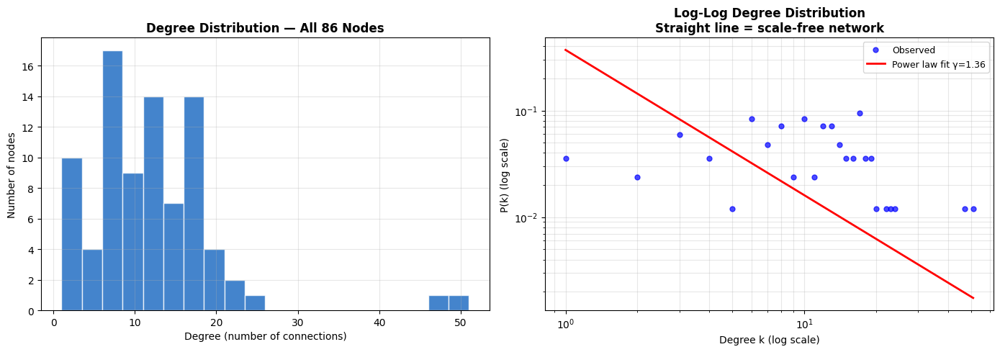

Saved: /content/drive/My Drive/Colab Notebooks/V3/L2_degree_distribution.png


In [ ]:
# ============================================================
# CELL 3 — Power law validation
# Fit degree distribution to P(k) ~ k^(-γ)
# γ between 2 and 3 = confirmed scale-free network
# γ tracked over time = market stability indicator
# When γ approaches 2, extreme events more likely
# ============================================================

try:
    import powerlaw
    POWERLAW_AVAILABLE = True
except ImportError:
    POWERLAW_AVAILABLE = False
    print("powerlaw not available — using manual fit")

def fit_power_law(G):
    """
    Fit power law to degree distribution.
    Returns γ exponent and fit quality (R² vs exponential).
    """
    degrees = [d for _, d in G.degree() if d > 0]
    if len(degrees) < 10:
        return None, None, None

    if POWERLAW_AVAILABLE:
        fit      = powerlaw.Fit(degrees, discrete=True,
                                xmin=1, verbose=False)
        gamma    = fit.power_law.alpha
        r_val, p = fit.distribution_compare(
            'power_law', 'exponential'
        )
        return float(gamma), float(r_val), degrees
    else:
        # Manual log-log linear regression
        from collections import Counter
        deg_counts = Counter(degrees)
        ks = np.array(sorted(deg_counts.keys()))
        ps = np.array([deg_counts[k] for k in ks],
                       dtype=float)
        ps /= ps.sum()

        log_k = np.log(ks[ps > 0])
        log_p = np.log(ps[ps > 0])

        if len(log_k) < 3:
            return None, None, degrees

        coeffs   = np.polyfit(log_k, log_p, 1)
        gamma    = -coeffs[0]
        r_sq     = np.corrcoef(log_k, log_p)[0, 1] ** 2
        return float(gamma), float(r_sq), degrees


gamma, r_val, degrees = fit_power_law(G_baseline)

print("Scale-free network validation:")
print(f"  Power law γ exponent: {gamma:.3f}" if gamma else "  Could not fit")
if r_val is not None:
    print(f"  Fit vs exponential R: {r_val:.3f}")
    print(f"  Scale-free confirmed: {2.0 <= gamma <= 3.0}"
          if gamma else "")
    if gamma:
        if 2.0 <= gamma <= 3.0:
            print(f"  Interpretation: Nigerian food-fuel-transport")
            print(f"  network is SCALE-FREE — hub structure confirmed")
            print(f"  Small number of indicators drive most price")
            print(f"  transmission across all cities")
        elif gamma < 2.0:
            print(f"  γ < 2: super-hub structure — extreme fragility")
        else:
            print(f"  γ > 3: less scale-free than typical networks")

# Plot degree distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.hist(degrees, bins=20, color='#1565C0',
        edgecolor='white', alpha=0.8)
ax.set_xlabel('Degree (number of connections)', fontsize=10)
ax.set_ylabel('Number of nodes', fontsize=10)
ax.set_title('Degree Distribution — All 86 Nodes',
             fontweight='bold')
ax.grid(True, alpha=0.3)

ax2 = axes[1]
from collections import Counter
deg_counts = Counter(degrees)
ks = sorted(deg_counts.keys())
ps = [deg_counts[k] / len(degrees) for k in ks]
ax2.loglog(ks, ps, 'bo', markersize=5, alpha=0.7,
           label='Observed')
if gamma:
    k_range = np.linspace(1, max(ks), 100)
    normaliser = sum(k ** (-gamma) for k in range(1, max(ks)+1))
    p_fit = [(k ** (-gamma)) / normaliser for k in k_range]
    ax2.loglog(k_range, p_fit, 'r-', linewidth=2,
               label=f'Power law fit γ={gamma:.2f}')
ax2.set_xlabel('Degree k (log scale)', fontsize=10)
ax2.set_ylabel('P(k) (log scale)', fontsize=10)
ax2.set_title('Log-Log Degree Distribution\n'
              'Straight line = scale-free network',
              fontweight='bold')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig(DRIVE_PATH + 'L2_degree_distribution.png',
            dpi=130, bbox_inches='tight')
plt.show()
print(f"Saved: {DRIVE_PATH}L2_degree_distribution.png")

In [ ]:
# ============================================================
# CELL 4 — Monthly dynamic network metrics (FULLY CORRECTED)
# Fixes: algebraic connectivity, Port_Harcourt city parsing
# ============================================================

def algebraic_connectivity(G):
    """
    Compute algebraic connectivity (second Laplacian eigenvalue).
    Uses weighted undirected version for non-zero results.
    """
    if G.number_of_nodes() < 2:
        return 0.0
    try:
        G_und = G.to_undirected()
        for u, v in G_und.edges():
            w1 = G[u][v]['weight'] if G.has_edge(u, v) else 0.0
            w2 = G[v][u]['weight'] if G.has_edge(v, u) else 0.0
            G_und[u][v]['weight'] = (w1 + w2) / 2.0
        L = nx.laplacian_matrix(
            G_und, weight='weight'
        ).toarray().astype(float)
        eigenvalues = np.sort(np.linalg.eigvalsh(L))
        return float(max(0.0, eigenvalues[1]))
    except Exception:
        return 0.0


def get_city_and_indicator(node, CITIES, NATIONAL_INDICATORS):
    """
    Correctly parse city and indicator from node name.
    Handles multi-word cities like Port_Harcourt.
    """
    if node in NATIONAL_INDICATORS:
        return 'National', node
    for c in CITIES:
        if node.endswith(f'_{c}'):
            indicator = node[: -(len(c) + 1)]
            return c, indicator
    # Fallback
    parts = node.split('_')
    return parts[-1], '_'.join(parts[:-1])


def update_edge_weights_from_rolling_var(
    G, rolling_df_dict, date, city
):
    G_updated = G.copy()
    rolling_df = rolling_df_dict.get(city)
    if rolling_df is None:
        return G_updated

    date_ts   = pd.Timestamp(date)
    available = rolling_df.index

    if date_ts not in available:
        nearest = available[
            np.argmin(np.abs(available - date_ts))
        ]
        date_ts = nearest

    try:
        row = rolling_df.loc[date_ts]
    except Exception:
        return G_updated

    for u, v, data in G_updated.edges(data=True):
        if data.get('city') != city:
            continue
        cause_ind  = u.replace(f'_{city}', '')
        effect_ind = v.replace(f'_{city}', '')
        pair_key   = f'{cause_ind}→{effect_ind}'

        if pair_key in row.index and not pd.isna(row[pair_key]):
            new_weight = float(row[pair_key])
            G_updated[u][v]['weight']        = abs(new_weight)
            G_updated[u][v]['signed_weight'] = new_weight
            G_updated[u][v]['colour'] = (
                'green' if new_weight >= 0 else 'red'
            )

    return G_updated


# Load rolling VAR results
print("Loading rolling VAR coefficients...")
rolling_df_dict = {}
for city in CITIES:
    fpath = DRIVE_PATH + f'S2b_rolling_var_{city}.csv'
    try:
        rdf = pd.read_csv(fpath, index_col=0,
                          parse_dates=True)
        rolling_df_dict[city] = rdf
        print(f"  {city}: {rdf.shape[0]} monthly windows  "
              f"{rdf.shape[1]} relationships")
    except Exception as e:
        print(f"  {city}: could not load — {e}")

# Monthly date range Jan 2024 to Jun 2026
monthly_dates = pd.date_range(
    start='2024-01-01',
    end='2026-06-01',
    freq='MS'
)

print(f"\nComputing monthly metrics for "
      f"{len(monthly_dates)} months...")
print("=" * 65)

monthly_metrics_rows = []

for date in monthly_dates:

    # Phase state for all cities this month
    month_phase = phase_state[
        phase_state['date'] == date
    ].set_index('city')

    # Build monthly graph with updated weights
    G_month = G_baseline.copy()
    for city in CITIES:
        G_month = update_edge_weights_from_rolling_var(
            G_month, rolling_df_dict, date, city
        )

    # Apply stress adjustment from Stage 3 basin proximity
    for city in CITIES:
        if city not in month_phase.index:
            continue
        if 'basin_proximity_score' in month_phase.columns:
            basin_prox = float(
                month_phase.loc[city, 'basin_proximity_score']
            )
        else:
            basin_prox = 0.25

        stress_mult = 1.0 - (basin_prox * 0.5)

        for u, v, data in G_month.edges(data=True):
            if data.get('city') == city:
                G_month[u][v]['stress_adjusted_weight'] = (
                    data['weight'] * stress_mult
                )

    # Network-level metrics
    alg_conn    = algebraic_connectivity(G_month)
    all_degrees = dict(G_month.degree())

    try:
        bc = nx.betweenness_centrality(
            G_month, weight='weight', normalized=True
        )
    except Exception:
        bc = {n: 0.0 for n in G_month.nodes()}

    gamma_month, _, _ = fit_power_law(G_month)

    # Per-node metrics — corrected city/indicator parsing
    for node in ALL_NODES:
        city, indicator = get_city_and_indicator(
            node, CITIES, NATIONAL_INDICATORS
        )

        if city in month_phase.index:
            dist_att    = float(month_phase.loc[city,
                'distance_to_attractor'])
            basin_prox  = float(month_phase.loc[city,
                'basin_proximity_score'])
            stress_flag = int(month_phase.loc[city,
                'stress_flag'])
        else:
            dist_att    = 0.0
            basin_prox  = 0.25
            stress_flag = 0

        out_edges = G_month.out_edges(node, data=True)
        edge_sum  = sum(
            d.get('stress_adjusted_weight',
                  d.get('weight', 0.0))
            for _, _, d in out_edges
        )

        monthly_metrics_rows.append({
            'date':                   date,
            'node':                   node,
            'city':                   city,
            'indicator':              indicator,
            'degree':                 all_degrees.get(node, 0),
            'betweenness':            round(bc.get(node, 0.0), 6),
            'out_edge_weight_sum':    round(edge_sum, 4),
            'algebraic_connectivity': round(alg_conn, 6),
            'power_law_gamma':        round(gamma_month, 4)
                                      if gamma_month is not None
                                      else None,
            'distance_to_attractor':  round(dist_att, 6),
            'basin_proximity_score':  round(basin_prox, 6),
            'stress_flag':            stress_flag,
        })

    # Progress print every 6 months
    if date.month in [1, 6, 12]:
        gamma_str = (f'{gamma_month:.3f}'
                     if gamma_month is not None else 'N/A')
        print(f"  {date.strftime('%Y-%m')}  "
              f"alg_conn={alg_conn:.4f}  "
              f"gamma={gamma_str}  "
              f"edges={G_month.number_of_edges()}")

monthly_df = pd.DataFrame(monthly_metrics_rows)
monthly_df.to_csv(
    DRIVE_PATH + 'L2_monthly_network_metrics.csv',
    index=False
)

print(f"\nMonthly metrics table: {monthly_df.shape}")
print(f"\nSample — verifying Port_Harcourt parsed correctly:")
ph_check = monthly_df[monthly_df['city'] == 'Port_Harcourt']
print(f"  Port_Harcourt rows: {len(ph_check)}")
print(ph_check[['node','city','indicator',
                'degree','betweenness']].head(5).to_string())

print(f"\nAlgebraic connectivity range: "
      f"{monthly_df['algebraic_connectivity'].min():.4f} to "
      f"{monthly_df['algebraic_connectivity'].max():.4f}")
print(f"Saved: {DRIVE_PATH}L2_monthly_network_metrics.csv")

Loading rolling VAR coefficients...
  Abuja: 66 monthly windows  17 relationships
  Bauchi: 66 monthly windows  17 relationships
  Kano: 66 monthly windows  17 relationships
  Lagos: 66 monthly windows  17 relationships
  Onitsha: 66 monthly windows  17 relationships
  Port_Harcourt: 66 monthly windows  17 relationships

Computing monthly metrics for 30 months...
  2024-01  alg_conn=0.0000  gamma=1.363  edges=500
  2024-06  alg_conn=0.0000  gamma=1.363  edges=500


Building network for Jan–Jun 2024...
Building network for Jul–Dec 2024...
Building network for Jan–Jun 2025...
Building network for Jul–Dec 2025...
Building network for Jan–Jun 2026...


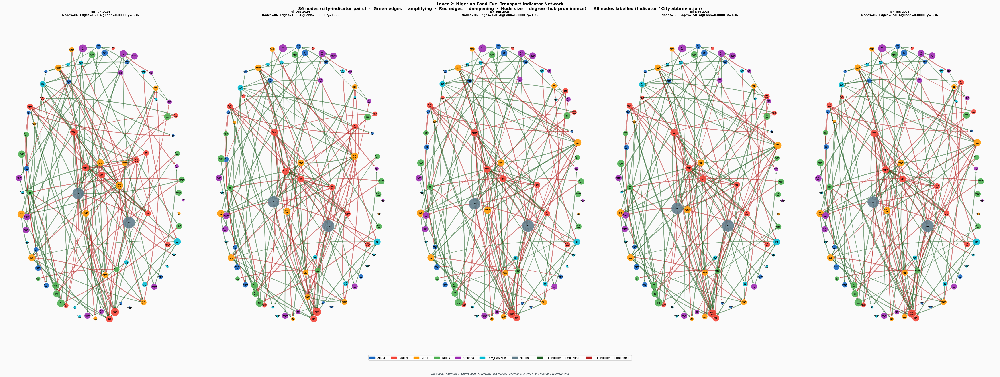

Saved: /content/drive/My Drive/Colab Notebooks/V3/L2_network_snapshots.png


In [ ]:
# ============================================================
# CELL 5 — Six-monthly network snapshots (CORRECTED)
# ============================================================

from sklearn.decomposition import PCA

SIX_MONTH_PERIODS = [
    ('2024-01-01', '2024-06-01', 'Jan–Jun 2024'),
    ('2024-07-01', '2024-12-01', 'Jul–Dec 2024'),
    ('2025-01-01', '2025-06-01', 'Jan–Jun 2025'),
    ('2025-07-01', '2025-12-01', 'Jul–Dec 2025'),
    ('2026-01-01', '2026-06-01', 'Jan–Jun 2026'),
]

CITY_COLORS = {
    'Abuja':         '#1565C0',
    'Bauchi':        '#F44336',
    'Kano':          '#FF9800',
    'Lagos':         '#4CAF50',
    'Onitsha':       '#9C27B0',
    'Port_Harcourt': '#00BCD4',
    'National':      '#607D8B',
}


def build_period_graph(start_date, end_date):
    period_dates = pd.date_range(
        start=start_date, end=end_date, freq='MS'
    )
    G_period = G_baseline.copy()
    weight_accumulator = {
        (u, v): [] for u, v in G_baseline.edges()
    }

    for date in period_dates:
        G_temp = G_baseline.copy()
        for city in CITIES:
            G_temp = update_edge_weights_from_rolling_var(
                G_temp, rolling_df_dict, date, city
            )
        for u, v, data in G_temp.edges(data=True):
            weight_accumulator[(u, v)].append(
                data.get('signed_weight', 0.0)
            )

    for (u, v), weights in weight_accumulator.items():
        if weights:
            avg_w = float(np.mean(weights))
            G_period[u][v]['weight']        = abs(avg_w)
            G_period[u][v]['signed_weight'] = avg_w
            G_period[u][v]['colour'] = (
                'green' if avg_w >= 0 else 'red'
            )

    return G_period


def plot_network_snapshot(G, title, ax, top_n_edges=120):
    np.random.seed(42)
    pos = nx.spring_layout(G, k=2.5, iterations=50, seed=42)

    degrees    = dict(G.degree())
    node_sizes = [max(30, degrees.get(n, 0) * 25)
                  for n in G.nodes()]

    node_colors = []
    for n in G.nodes():
        if n in NATIONAL_INDICATORS:
            node_colors.append(CITY_COLORS['National'])
        else:
            city = n.split('_')[-1]
            node_colors.append(CITY_COLORS.get(city, '#BDBDBD'))

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=node_sizes,
        node_color=node_colors,
        alpha=0.85
    )

    all_edges = sorted(
        G.edges(data=True),
        key=lambda x: x[2].get('weight', 0),
        reverse=True
    )[:top_n_edges]

    edge_list   = [(u, v) for u, v, _ in all_edges]
    edge_colors = [
        '#2E7D32' if d.get('colour') == 'green' else '#B71C1C'
        for _, _, d in all_edges
    ]
    edge_widths = [
        min(3.0, max(0.3, d.get('weight', 0.1) * 2))
        for _, _, d in all_edges
    ]

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edgelist=edge_list,
        edge_color=edge_colors,
        width=edge_widths,
        alpha=0.6,
        arrows=True,
        arrowsize=8,
        connectionstyle='arc3,rad=0.1'
    )

    degree_thresh = np.percentile(list(degrees.values()), 85)
    hub_labels    = {
        n: n.replace(f'_{n.split("_")[-1]}', '\n') + n.split('_')[-1]
        for n, d in degrees.items()
        if d >= degree_thresh
    }
    nx.draw_networkx_labels(
        G, pos, labels=hub_labels,
        ax=ax, font_size=5, font_weight='bold'
    )

    alg_conn  = algebraic_connectivity(G)
    gamma_v, _, _ = fit_power_law(G)
    gamma_str = f'{gamma_v:.2f}' if gamma_v is not None else 'N/A'

    ax.set_title(
        f'{title}\n'
        f'Nodes={G.number_of_nodes()}  '
        f'Edges={len(edge_list)}  '
        f'AlgConn={alg_conn:.3f}  '
        f'γ={gamma_str}',
        fontweight='bold', fontsize=9
    )
    ax.axis('off')


# Build and plot all five snapshots
fig, axes = plt.subplots(1, 5, figsize=(35, 12))
fig.suptitle(
    'Layer 2: Nigerian Food-Fuel-Transport Indicator Network\n'
    '86 nodes (city-indicator pairs)  ·  '
    'Green edges = amplifying  ·  Red edges = dampening  ·  '
    'Node size = degree (hub prominence)',
    fontsize=13, fontweight='bold'
)

for idx, (start, end, label) in enumerate(SIX_MONTH_PERIODS):
    print(f"Building network for {label}...")
    G_period = build_period_graph(start, end)
    plot_network_snapshot(G_period, label, axes[idx])

legend_patches = [
    mpatches.Patch(color=CITY_COLORS[c], label=c)
    for c in CITY_COLORS
]
legend_patches += [
    mpatches.Patch(color='#2E7D32', label='+ coeff (amplifying)'),
    mpatches.Patch(color='#B71C1C', label='− coeff (dampening)'),
]
fig.legend(
    handles=legend_patches,
    loc='lower center',
    ncol=9,
    fontsize=8,
    bbox_to_anchor=(0.5, -0.03)
)

plt.tight_layout()
fname = DRIVE_PATH + 'L2_network_snapshots.png'
plt.savefig(fname, dpi=120, bbox_inches='tight')
plt.show()
print(f"Saved: {fname}")

In [ ]:
# ============================================================
# CELL 6 — Layer 2 Summary (CORRECTED)
# ============================================================

print("=" * 65)
print("LAYER 2 COMPLETE — DYNAMIC INDICATOR NETWORK SUMMARY")
print("=" * 65)

monthly_df = pd.read_csv(
    DRIVE_PATH + 'L2_monthly_network_metrics.csv',
    parse_dates=['date']
)

# Algebraic connectivity trend
print("\nAlgebraic Connectivity trend (network cohesion):")
print("Higher = more resilient  Lower = more fragile")
alg_by_month = (
    monthly_df
    .groupby('date')['algebraic_connectivity']
    .first()
    .reset_index()
)
for _, row in alg_by_month.iterrows():
    bar_len = int(row['algebraic_connectivity'] * 50)
    bar     = '█' * max(0, bar_len)
    print(f"  {row['date'].strftime('%Y-%m')}  "
          f"{row['algebraic_connectivity']:.4f}  {bar}")

# Top hub nodes
print("\nTop 15 hub nodes (mean degree Jan 2024–Jun 2026):")
hub_summary = (
    monthly_df
    .groupby('node')['degree']
    .mean()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)
for _, row in hub_summary.iterrows():
    print(f"  {row['node']:<35} mean_degree={row['degree']:.1f}")

# Power law gamma trend
print("\nPower law γ trend (2.0–3.0 = scale-free confirmed):")
gamma_by_month = (
    monthly_df
    .groupby('date')['power_law_gamma']
    .first()
    .reset_index()
    .dropna(subset=['power_law_gamma'])
)
for _, row in gamma_by_month.iterrows():
    gamma_val = row['power_law_gamma']
    flag      = ' ← fragility warning' if gamma_val < 2.1 else ''
    gamma_str = f'{gamma_val:.3f}'
    print(f"  {row['date'].strftime('%Y-%m')}  "
          f"gamma={gamma_str}{flag}")

# Most connected indicator per city
print("\nMost connected indicator per city "
      "(highest mean betweenness):")
for city in CITIES:
    city_df = monthly_df[monthly_df['city'] == city]
    if city_df.empty:
        continue
    bc_by_node = city_df.groupby('node')['betweenness'].mean()
    if bc_by_node.empty:
        continue
    top_node = bc_by_node.idxmax()
    top_bc   = bc_by_node.max()
    indicator = top_node.replace(f'_{city}', '')
    print(f"  {city:<15} hub={indicator:<20} "
          f"betweenness={top_bc:.4f}")

print()
print("=" * 65)
print("FILES SAVED TO DRIVE:")
for fname in [
    'L2_monthly_network_metrics.csv',
    'L2_network_snapshots.png',
    'L2_degree_distribution.png',
]:
    print(f"  {DRIVE_PATH}{fname}")

print()
print("MESA AGENT INPUTS FROM LAYER 2:")
print("  Each agent observes per step:")
print("  - algebraic_connectivity  (network fragility)")
print("  - betweenness (own node)  (hub importance)")
print("  - out_edge_weight_sum     (transmission strength)")
print("  - stress_adjusted_weight  (basin-corrected signal)")
print()
print("NEXT STEP: Mesa A2C Simulation")
print("  Simulation period: Jan 2024 to Jun 2026 (real data)")
print("  Forecast period:   Jul 2026 to Dec 2027 (LSTM)")

LAYER 2 COMPLETE — DYNAMIC INDICATOR NETWORK SUMMARY

Algebraic Connectivity trend (network cohesion):
Higher = more resilient  Lower = more fragile
  2024-01  0.0000  
  2024-02  0.0000  
  2024-03  0.0000  
  2024-04  0.0000  
  2024-05  0.0000  
  2024-06  0.0000  
  2024-07  0.0000  
  2024-08  0.0000  
  2024-09  0.0000  
  2024-10  0.0000  
  2024-11  0.0000  
  2024-12  0.0000  
  2025-01  0.0000  
  2025-02  0.0000  
  2025-03  0.0000  
  2025-04  0.0000  
  2025-05  0.0000  
  2025-06  0.0000  
  2025-07  0.0000  
  2025-08  0.0000  
  2025-09  0.0000  
  2025-10  0.0000  
  2025-11  0.0000  
  2025-12  0.0000  
  2026-01  0.0000  
  2026-02  0.0000  
  2026-03  0.0000  
  2026-04  0.0000  
  2026-05  0.0000  
  2026-06  0.0000  

Top 15 hub nodes (mean degree Jan 2024–Jun 2026):
  CBN_MPR                             mean_degree=51.0
  USD_NGN                             mean_degree=47.0
  Chicken_Bauchi                      mean_degree=24.0
  Bus_Intercity_Onitsha            